# SATO 2015 — nhận diện khách hàng đã rời dịch vụ
## 1. Bài này muốn tìm hiểu điều gì?
Nhà mạng có thông tin về thời gian sử dụng, cuộc gọi, doanh thu và loại dịch vụ của khách hàng. Bài này tìm hiểu các thông tin đó, rồi xây dựng mô hình để phân biệt hai nhóm: **khách đang hoạt động (`Active`)** và **khách đã rời dịch vụ (`Churned`)**. Cột `Class` cho biết kết quả thật để mô hình học và để kiểm tra dự đoán.

Dữ liệu có **2000 hồ sơ và 14 cột**: 13 cột mô tả khách hàng và 1 cột kết quả. Theo [mô tả của tác giả trên Kaggle](https://www.kaggle.com/datasets/mahreen/sato2015), dữ liệu được thu thập từ một nhà mạng Nam Á, gồm thông tin doanh thu tháng 8–9/2015. Nguồn cho phép sử dụng theo giấy phép CC0.

Tác giả đã chuẩn bị sẵn 1000 hồ sơ mỗi nhóm. Vì vậy, tỷ lệ 50/50 chỉ mô tả **bộ dữ liệu này**, không có nghĩa một nửa khách hàng của nhà mạng đã rời đi.

Bài đi theo ba câu hỏi: **Dữ liệu có vấn đề gì? Hai nhóm khách khác nhau ở đâu? Mô hình phân biệt hai nhóm tốt đến mức nào?** Trước tiên ta đọc và hiểu dữ liệu, sau đó tìm hiểu bằng bảng/biểu đồ, chuẩn bị dữ liệu cho mô hình, rồi kiểm tra kết quả trên các hồ sơ để riêng. Những điều nguồn chưa mô tả đầy đủ được nêu ở cuối bài.

## 2. Đọc dữ liệu và xem 5 hồ sơ đầu
Bảng dưới hiển thị đủ 14 cột; có thể cuộn ngang để xem hết. Mỗi hàng là một hồ sơ theo mô tả nguồn. Đây mới là bước đọc tệp: các ô trống và giá trị gốc vẫn được giữ lại. Khi chạy trên Colab, code sẽ tải từ Kaggle nếu chưa có tệp trong máy.

In [1]:
# Display numbers with a decimal comma and no thousands separator.
import re
from decimal import Decimal

def _decimal_comma_text(text):
    scientific = r"(?<![\w.,])[+-]?(?:\d+(?:[.,]\d+)?|\.\d+)[eE][+-]?\d+(?!\w)"
    text = re.sub(scientific, lambda m: format(Decimal(m.group().replace(",", ".")), "f"), str(text))
    pattern = r"(?<![\w.,])(?:[1-9]\d{0,2}(?:,\d{3})+(?:\.\d+)?|\d+\.\d+|\d+,\d+)(?!\w|[.,]\d)"
    def render(match):
        token = match.group()
        if re.fullmatch(r"[1-9]\d{0,2}(?:,\d{3})+(?:\.\d+)?", token):
            token = token.replace(",", "")
            if "." not in token:
                return token
        else:
            token = token.replace(",", ".")
        result = format(Decimal(token), ".2f")
        return result.replace(".", ",")
    return re.sub(pattern, render, str(text))

def _frame_html(frame, index=False):
    def source_number(value):
        if isinstance(value, str) and re.fullmatch(r"[+-]?\d+(?:\.\d+)?(?:[eE][+-]?\d+)?", value):
            return _decimal_comma_text(value)
        return str(value)
    def plain_float(value):
        result = format(value, ".2f")
        return _decimal_comma_text(result)
    formatters = {c: source_number for c in frame.columns if frame[c].dtype == object}
    if 'count' in frame.columns and frame['count'].dtype != object:
        formatters['count'] = lambda value: str(int(value))
    return frame.to_html(index=index, decimal=",", formatters=formatters, float_format=plain_float)

def _format_plot_numbers(figure):
    from matplotlib.ticker import ScalarFormatter
    class DecimalCommaFormatter(ScalarFormatter):
        def __init__(self):
            super().__init__(useOffset=False)
            self.set_scientific(False)
        def __call__(self, value, pos=None):
            if value == int(value):
                return str(int(value))
            return format(value, ".2f").replace(".", ",")
        def get_offset(self):
            return super().get_offset().replace(".", ",")
    for ax in figure.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if isinstance(axis.get_major_formatter(), ScalarFormatter):
                axis.set_major_formatter(DecimalCommaFormatter())
        for label in ax.texts:
            label.set_text(_decimal_comma_text(label.get_text()))

import pandas as pd
from IPython.display import display, HTML
from pathlib import Path
import io, zipfile

source_path = Path("data/tabular_sato/sato2015.csv")
if source_path.exists():
    raw = pd.read_csv(source_path, keep_default_na=False, dtype=str)
else:
    import requests

    response = requests.get(
        "https://www.kaggle.com/api/v1/datasets/download/mahreen/sato2015", timeout=90
    )
    response.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
        csv_files = [p for p in archive.namelist() if p.lower().endswith(".csv")]
        if len(csv_files) != 1:
            raise ValueError("Unexpected source archive contents")
        raw = pd.read_csv(archive.open(csv_files[0]), keep_default_na=False, dtype=str)
with pd.option_context("display.max_columns", None):
    display(HTML(_frame_html(raw.head(5), index=True)))


,network_age,Aggregate_Total_Rev,Aggregate_SMS_Rev,Aggregate_Data_Rev,Aggregate_Data_Vol,Aggregate_Calls,Aggregate_ONNET_REV,Aggregate_OFFNET_REV,Aggregate_complaint_count,aug_user_type,sep_user_type,aug_fav_a,sep_fav_a,Class
0,1914,"1592,72","23,26","2,50","11,61",375,25523,99000,1,2G,2G,telenor,mobilink,Churned
1,2073,"1404,15","174,45","27,50","2531,72",389,14584,77299,1,2G,2G,mobilink,ufone,Churned
2,3139,"85,55","14,34",5,"29133,06",15,477,4194,1,Other,Other,ptcl,telenor,Churned
3,139,"2315,23","19,25","52,50","267441,28",636,50316,52400,2,2G,2G,telenor,ufone,Active
4,139,"227,86","2,95","42,50","1461620,52",17,2568,1701,1,,,mobilink,ufone,Active


### Bảng mô tả thuộc tính
Bảng dưới giúp đọc nhanh từng cột: **tên thuộc tính**, **loại thông tin** và **ý nghĩa**. Cách phân loại dựa trên ý nghĩa của thuộc tính: Numerical là đại lượng dạng số; Categorical là tên nhóm; Target là nhãn cần dự đoán.

Code khai báo loại và mô tả cho từng thuộc tính, rồi tạo bảng theo đúng thứ tự cột trong tệp. Đây là bảng giới thiệu dữ liệu, chưa phải bước xử lý dữ liệu.

In [2]:
from IPython.display import HTML

# Type and meaning of each source column.
feature_definitions = {'network_age': ('Numerical', 'Thời gian đã sử dụng dịch vụ; card không ghi rõ đơn vị'),
 'Aggregate_Total_Rev': ('Numerical', 'Doanh thu tổng gộp tháng 8–9/2015, rupee'),
 'Aggregate_SMS_Rev': ('Numerical', 'Doanh thu gộp từ SMS'),
 'Aggregate_Data_Rev': ('Numerical', 'Doanh thu gộp từ dịch vụ dữ liệu'),
 'Aggregate_Data_Vol': ('Numerical', 'Dung lượng sử dụng dữ liệu; chưa rõ đơn vị'),
 'Aggregate_Calls': ('Numerical', 'Tổng số cuộc gọi'),
 'Aggregate_ONNET_REV': ('Numerical', 'Doanh thu gộp từ liên lạc nội mạng'),
 'Aggregate_OFFNET_REV': ('Numerical', 'Doanh thu gộp từ liên lạc ngoại mạng'),
 'Aggregate_complaint_count': ('Numerical', 'Tổng số khiếu nại'),
 'aug_user_type': ('Categorical', 'Loại dịch vụ tháng 8: 2G/3G/Other'),
 'sep_user_type': ('Categorical', 'Loại dịch vụ tháng 9: 2G/3G/Other'),
 'aug_fav_a': ('Categorical', 'Mạng khác được liên lạc nhiều nhất tháng 8'),
 'sep_fav_a': ('Categorical', 'Mạng khác được liên lạc nhiều nhất tháng 9'),
 'Class': ('Target', 'Nhãn nguồn: Active=0, Churned=1')}

feature_descriptions = pd.DataFrame([
    {
        "Tên thuộc tính": column,
        "Loại": feature_definitions[column][0],
        "Ý nghĩa": feature_definitions[column][1],
    }
    for column in raw.columns
])
display(HTML(feature_descriptions.to_html(index=False)))


Tên thuộc tính,Loại,Ý nghĩa
network_age,Numerical,Thời gian đã sử dụng dịch vụ; card không ghi rõ đơn vị
Aggregate_Total_Rev,Numerical,"Doanh thu tổng gộp tháng 8–9/2015, rupee"
Aggregate_SMS_Rev,Numerical,Doanh thu gộp từ SMS
Aggregate_Data_Rev,Numerical,Doanh thu gộp từ dịch vụ dữ liệu
Aggregate_Data_Vol,Numerical,Dung lượng sử dụng dữ liệu; chưa rõ đơn vị
Aggregate_Calls,Numerical,Tổng số cuộc gọi
Aggregate_ONNET_REV,Numerical,Doanh thu gộp từ liên lạc nội mạng
Aggregate_OFFNET_REV,Numerical,Doanh thu gộp từ liên lạc ngoại mạng
Aggregate_complaint_count,Numerical,Tổng số khiếu nại
aug_user_type,Categorical,Loại dịch vụ tháng 8: 2G/3G/Other


**Cách dùng bảng:** Có **9 thuộc tính Numerical**, chẳng hạn doanh thu tổng và số cuộc gọi; ta sẽ xem các mức giá trị và tính trung bình, trung vị. Có **4 thuộc tính Categorical**, chẳng hạn loại dịch vụ `2G`/`3G`; ta sẽ đếm số khách của từng nhóm. `Class` là **Target**, cho biết khách đang hoạt động (`Active`) hay đã rời dịch vụ (`Churned`), nên được tách riêng khỏi 13 đầu vào.

Tiếp theo, ta giải thích các chữ viết tắt và tạo bản dữ liệu dùng để tính toán.

### 2.1. Đọc tên cột và chuẩn bị dữ liệu để tính toán
Trước khi tính trung bình hoặc vẽ biểu đồ, ta cần hiểu tên cột và giúp Python đọc đúng loại dữ liệu.

**Các từ thường gặp trong tên cột:**

| Từ trong tên cột | Ý nghĩa |
|---|---|
| `Rev` hoặc `REV` | Doanh thu. |
| `Vol` | Dung lượng dữ liệu đã sử dụng. |
| `SMS` | Tin nhắn. |
| `ONNET` | Liên lạc trong cùng mạng. |
| `OFFNET` | Liên lạc tới mạng khác. |
| `aug` | Tháng 8. |
| `sep` | Tháng 9. |
| `Aggregate` | Giá trị đã được tổng hợp trong dữ liệu nguồn. |

Ví dụ, `Aggregate_SMS_Rev` là doanh thu từ tin nhắn đã được tổng hợp. Nguồn chưa nêu đầy đủ đơn vị của một số cột; những trường hợp đó được ghi chú trong bảng mô tả thuộc tính.

**Hai cột tên mạng và các giá trị cần phân biệt:**

- `aug_fav_a` và `sep_fav_a` cho biết mạng khác được khách liên lạc nhiều nhất trong tháng 8 và tháng 9. Chúng không cho biết khách đang đăng ký dịch vụ của mạng nào.
- `Other` là nhóm “khác” được ghi sẵn trong nguồn. Giá trị này vẫn có thông tin, khác với một ô trống.
- Mã `'0'` trong `aug_fav_a` chưa được nguồn giải thích. Bài giữ nguyên mã này, không tự gán tên mạng hoặc coi nó là ô trống.

**Code bên dưới làm gì?**

Ở bước đọc tệp, `raw` giữ các giá trị dưới dạng chuỗi, kể cả những số như `"375"`. Code tạo thêm một bản tên `view` để dùng cho các phép tính:

1. Đánh dấu ô trống bằng `NaN`, tức “chưa có dữ liệu”. Bước này chỉ đánh dấu, chưa điền giá trị thay thế.
2. Chuyển 9 cột số từ chuỗi sang số, chẳng hạn `"375"` thành số `375`, để có thể tính toán.
3. Đổi nhãn `Class` thành mã số: `Active` → `0` (đang hoạt động), `Churned` → `1` (đã rời dịch vụ). Ý nghĩa nhãn vẫn giữ nguyên.

Từ đây, các bảng thống kê và biểu đồ dùng bản `view`. Bản `raw` được giữ để đối chiếu với dữ liệu ban đầu.

In [3]:
import importlib.util, subprocess, sys

packages = {
    "numpy": "numpy",
    "scipy": "scipy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
}
needed = [p for m, p in packages.items() if importlib.util.find_spec(m) is None]
if needed:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *needed])
import numpy as np, matplotlib.pyplot as plt, seaborn as sns, json, hashlib
from IPython.display import HTML
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
)
from sklearn.inspection import permutation_importance

SEED = 42
OUT = Path("outputs/tabular_sato")
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False}
)
NUM = [
    "network_age",
    "Aggregate_Total_Rev",
    "Aggregate_SMS_Rev",
    "Aggregate_Data_Rev",
    "Aggregate_Data_Vol",
    "Aggregate_Calls",
    "Aggregate_ONNET_REV",
    "Aggregate_OFFNET_REV",
    "Aggregate_complaint_count",
]
CAT = ["aug_user_type", "sep_user_type", "aug_fav_a", "sep_fav_a"]
FEATURES = NUM + CAT
MEANING = {
    "network_age": "Elapsed time using the carrier; card does not specify the unit",
    "Aggregate_Total_Rev": "Aggregated total revenue (rupees), Aug–Sep 2015",
    "Aggregate_SMS_Rev": "Aggregated SMS revenue",
    "Aggregate_Data_Rev": "Aggregated data-service revenue",
    "Aggregate_Data_Vol": "Aggregated data-service volume; unit not specified",
    "Aggregate_Calls": "Aggregated call count",
    "Aggregate_ONNET_REV": "Aggregated on-network revenue",
    "Aggregate_OFFNET_REV": "Aggregated off-network revenue",
    "Aggregate_complaint_count": "Aggregated complaint count",
    "aug_user_type": "August service type: 2G / 3G / Other",
    "sep_user_type": "September service type: 2G / 3G / Other",
    "aug_fav_a": "August most-contacted other network",
    "sep_fav_a": "September most-contacted other network",
    "Class": "Source customer status: Active=0, Churned=1",
}
VI_MEANING = {
    "network_age": "Thời gian đã sử dụng dịch vụ; card không ghi rõ đơn vị",
    "Aggregate_Total_Rev": "Doanh thu tổng gộp tháng 8–9/2015, rupee",
    "Aggregate_SMS_Rev": "Doanh thu gộp từ SMS",
    "Aggregate_Data_Rev": "Doanh thu gộp từ dịch vụ dữ liệu",
    "Aggregate_Data_Vol": "Dung lượng sử dụng dữ liệu; chưa rõ đơn vị",
    "Aggregate_Calls": "Tổng số cuộc gọi",
    "Aggregate_ONNET_REV": "Doanh thu gộp từ liên lạc nội mạng",
    "Aggregate_OFFNET_REV": "Doanh thu gộp từ liên lạc ngoại mạng",
    "Aggregate_complaint_count": "Tổng số khiếu nại",
    "aug_user_type": "Loại dịch vụ tháng 8: 2G/3G/Other",
    "sep_user_type": "Loại dịch vụ tháng 9: 2G/3G/Other",
    "aug_fav_a": "Mạng khác được liên lạc nhiều nhất tháng 8",
    "sep_fav_a": "Mạng khác được liên lạc nhiều nhất tháng 9",
    "Class": "Nhãn nguồn: Active=0, Churned=1",
}


class ChurnStudy:
    def view(self, source):
        assert set(source.columns) == set(FEATURES + ["Class"])
        data = source.replace("", np.nan).copy()
        for c in NUM:
            data[c] = pd.to_numeric(data[c], errors="raise")
        assert set(data.Class) == {"Active", "Churned"}
        data["Class"] = data.Class.map({"Active": 0, "Churned": 1})
        return data

    def model_inputs(self, data):
        result = data[FEATURES].copy()
        result["network_age"] = result.network_age.mask(result.network_age.lt(0))
        return result


snapshot = raw.copy(deep=True)
study = ChurnStudy()
view = study.view(raw)
N = len(view)
assert N == 2000 and len(raw.columns) == 14 and raw.drop(columns="Class").duplicated().sum() == 0
figures = []


def table(df):
    display(HTML(_frame_html(df)))


def sample(df):
    table(df.head(5))




def finish(k):
    _format_plot_numbers(plt.gcf())
    plt.tight_layout()
    plt.savefig(OUT / (k + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
    figures.append(k)




schema = pd.DataFrame(
    [
        {
            "field": c,
            "English meaning": MEANING[c],
            "meaning_vi": VI_MEANING[c],
            "role": "numeric X" if c in NUM else "categorical X" if c in CAT else "target y",
            "missing": view[c].isna().sum(),
            "distinct": view[c].nunique(),
        }
        for c in raw
    ]
)
schema.to_csv(OUT / "schema.csv", index=False)
print(
    "Original shape:",
    raw.shape,
    "| Full duplicate rows:",
    raw.duplicated().sum(),
    "| Duplicate predictor signatures:",
    raw.drop(columns="Class").duplicated().sum(),
)


Original shape: (2000, 14) | Full duplicate rows: 0 | Duplicate predictor signatures: 0


### 2.2. Có giá trị nào cần kiểm tra không?
Bảng đầu cho biết giá trị nhỏ nhất, lớn nhất, số giá trị âm và số giá trị 0 của từng cột số. Bảng tiếp theo chỉ ra **5 hồ sơ có thời gian sử dụng âm**. Thời gian đã sử dụng không thể âm, nên ở bước chuẩn bị mô hình ta sẽ coi riêng giá trị đó là chưa biết; các thông tin còn lại của khách vẫn được giữ.

Các số 0 ở doanh thu chưa đủ để kết luận nhập sai. Tương tự, mã `'0'` ở tên mạng và nhóm `Other` không được tự đổi thành ô trống. Nguồn cũng chưa xác nhận các cột doanh thu dùng chung thang đơn vị, nên bài không lấy tổng doanh thu nội/ngoại mạng để kiểm tra bằng doanh thu tổng.

In [4]:
quality = pd.DataFrame(
    [
        {
            "field": c,
            "min": view[c].min(),
            "max": view[c].max(),
            "negative": view[c].lt(0).sum(),
            "zero": view[c].eq(0).sum(),
        }
        for c in NUM
    ]
)
table(quality)
print("All negative elapsed-duration records:")
table(
    view.loc[view.network_age.lt(0), ["network_age", "Aggregate_Total_Rev", "Class"]].reset_index(
        names="row_id"
    )
)
table(
    pd.DataFrame(
        [
            {
                "field": "aug_fav_a",
                "source_code": "0",
                "records": raw.aug_fav_a.eq("0").sum(),
                "interpretation": "Mã 0 có trong dữ liệu nhưng nguồn chưa giải thích ý nghĩa; giữ nguyên, không tự coi là ô trống.",
            },
            {
                "field": "aug_user_type",
                "source_code": "Other",
                "records": raw.aug_user_type.eq("Other").sum(),
                "interpretation": "Nhóm “khác” được ghi sẵn trong dữ liệu; không phải giá trị thiếu.",
            },
            {
                "field": "aug_user_type",
                "source_code": "empty",
                "records": raw.aug_user_type.eq("").sum(),
                "interpretation": "Ô trống trong dữ liệu gốc; được xem là giá trị thiếu.",
            },
        ]
    )
)
quality.to_csv(OUT / "quality_summary.csv", index=False)


field,min,max,negative,zero
network_age,"-8,00","5451,00",5,0
Aggregate_Total_Rev,"4,91","24438,83",0,0
Aggregate_SMS_Rev,"0,00","873,98",0,299
Aggregate_Data_Rev,"0,00","8295,00",0,394
Aggregate_Data_Vol,"0,06","155031212,80",0,0
Aggregate_Calls,"1,00","5727,00",0,0
Aggregate_ONNET_REV,"0,00","381174,00",0,408
Aggregate_OFFNET_REV,"0,00","431440,00",0,56
Aggregate_complaint_count,"1,00","49,00",0,0


All negative elapsed-duration records:


row_id,network_age,Aggregate_Total_Rev,Class
594,-8,"485,70",1
595,-5,"857,10",1
596,-4,"2898,82",1
597,-3,"307,12",1
598,-2,"130,58",1


field,source_code,records,interpretation
aug_fav_a,0,59,"Mã 0 có trong dữ liệu nhưng nguồn chưa giải thích ý nghĩa; giữ nguyên, không tự coi là ô trống."
aug_user_type,Other,374,Nhóm “khác” được ghi sẵn trong dữ liệu; không phải giá trị thiếu.
aug_user_type,empty,245,Ô trống trong dữ liệu gốc; được xem là giá trị thiếu.


## 3. Chia dữ liệu để học và kiểm tra
Ta để riêng ba phần dữ liệu:

| Phần dữ liệu | Số hồ sơ | Dùng để làm gì? |
|---|---:|---|
| Tập học — train | 1400 | Tìm hiểu dữ liệu chi tiết và huấn luyện mô hình |
| Tập chọn mô hình — validation | 300 | So sánh và chọn mô hình |
| Tập kiểm tra cuối — test | 300 | Kiểm tra mô hình đã chọn |

Mỗi phần có số khách đang hoạt động và đã rời dịch vụ bằng nhau. `random_state=42` giúp chạy lại vẫn nhận cùng cách chia. Ba bảng 5 hàng dưới chỉ giúp xem ví dụ hồ sơ của từng phần; bảng tổng hợp mới cho biết số lượng đầy đủ.

Từ phần 4 đến 7, các biểu đồ dùng **1400 hồ sơ của tập học**. Các ô thiếu chưa được điền ở bước này. File không có mã khách hàng nên chỉ kiểm tra được các dòng và bộ thông tin trùng nhau, chưa xác nhận được mỗi khách chỉ xuất hiện một lần.

In [5]:
train_idx, hold_idx = train_test_split(
    view.index, test_size=0.30, stratify=view.Class, random_state=SEED
)
val_idx, test_idx = train_test_split(
    hold_idx, test_size=0.5, stratify=view.loc[hold_idx, "Class"], random_state=SEED
)
parts = {"train": train_idx, "validation": val_idx, "test": test_idx}
assignment = pd.DataFrame({"row_id": view.index, "split": ""})
for label, idx in parts.items():
    assignment.loc[idx, "split"] = label
for l, r in [("train", "validation"), ("train", "test"), ("validation", "test")]:
    assert not (set(parts[l]) & set(parts[r]))
assert assignment.split.ne("").all() and assignment.row_id.is_unique
split_table = pd.DataFrame(
    [
        {
            "split": label,
            "rows": len(idx),
            "row_share": len(idx) / N,
            "Active_0": view.loc[idx, "Class"].eq(0).sum(),
            "Churned_1": view.loc[idx, "Class"].eq(1).sum(),
            "positive_rate": view.loc[idx, "Class"].mean(),
        }
        for label, idx in parts.items()
    ]
)
table(split_table)
for label, idx in parts.items():
    print(label, "five source records")
    sample(view.loc[idx, ["network_age", "Aggregate_Total_Rev", "aug_user_type", "Class"]])
assignment.to_csv(OUT / "split_assignments.csv", index=False)
split_table.to_csv(OUT / "split_counts.csv", index=False)
eda = view.loc[train_idx].copy()
M = len(eda)


split,rows,row_share,Active_0,Churned_1,positive_rate
train,1400,"0,70",700,700,"0,50"
validation,300,"0,15",150,150,"0,50"
test,300,"0,15",150,150,"0,50"


train five source records


network_age,Aggregate_Total_Rev,aug_user_type,Class
149,"152,45",3G,0
1092,"135,38",Other,1
117,"1367,68",3G,1
399,"682,79",3G,1
1067,"155,57",3G,1


validation five source records


network_age,Aggregate_Total_Rev,aug_user_type,Class
1356,"812,46",3G,1
243,"117,27",Other,1
171,"403,45",NaN,1
842,"306,29",2G,1
473,"509,05",3G,1


test five source records


network_age,Aggregate_Total_Rev,aug_user_type,Class
1779,"1219,90",3G,1
1174,"1300,94",Other,1
1038,"261,84",2G,0
2604,"1916,85",3G,0
4075,"1689,97",3G,0


### 3.1. Có bao nhiêu khách thuộc mỗi nhóm?
Hai cột biểu diễn số hồ sơ đang hoạt động và đã rời dịch vụ trong toàn bộ tệp. Với mỗi nhóm, lấy số hồ sơ nhóm đó chia cho 2000 để tính tỷ lệ. Bảng 5 hàng chỉ minh họa cách đếm: hồ sơ đã rời dịch vụ đóng góp 1, hồ sơ còn hoạt động đóng góp 0 vào tổng lớp 1.

Class,contributes_churn
1,1
1,1
1,1
0,0
0,0


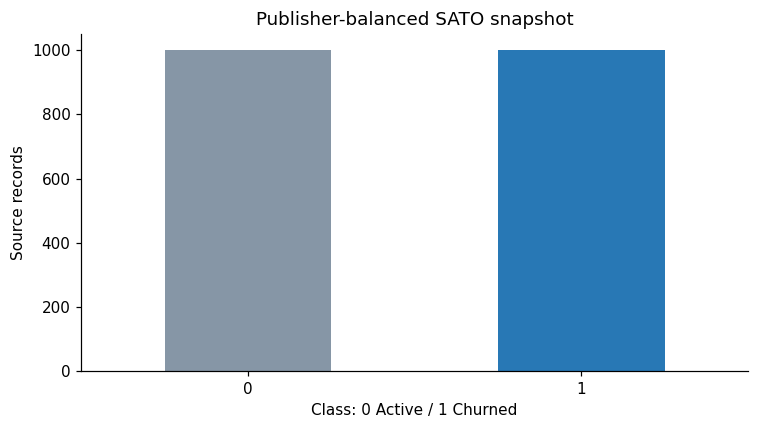

In [6]:
target = view.Class.value_counts().sort_index()
sample(view[["Class"]].assign(contributes_churn=view.Class.eq(1).astype(int)))
fig, ax = plt.subplots(figsize=(7, 4))
target.plot.bar(ax=ax, color=["#8696a6", "#2878b5"], rot=0)
ax.set(
    xlabel="Class: 0 Active / 1 Churned",
    ylabel="Source records",
    title="Publisher-balanced SATO snapshot",
)
finish("target")


**Ví dụ tính từ dữ liệu:**

Churned: 1000/2000=50,00%; Active: 1000/2000=50,00%

**Nhận xét:** Mỗi nhóm có 1000 hồ sơ. Nếu chỉ luôn đoán một nhóm, ta đúng 50% nhưng chưa phân biệt được khách hàng. Đó là mốc đơn giản để so mô hình.

## 4. Thông tin nào còn thiếu trong tập học?
### 4.1. Đếm ô thiếu theo từng cột
Biểu đồ thanh ngang cho biết cột nào thiếu nhiều thông tin hơn. Ví dụ, tỷ lệ thiếu loại dịch vụ tháng 8 được tính bằng **số hồ sơ thiếu cột đó / 1400 × 100**.

Bảng 5 hàng minh họa cờ thiếu: 1 = ô trống, 0 = có dữ liệu. Bảng tiếp theo tổng hợp đủ 13 đầu vào. Những thời gian âm vẫn được báo riêng ở phần 2.2, chưa gộp vào số ô trống của nguồn.

aug_user_type,sep_user_type,aug_missing
3G,2G,0
Other,Other,0
3G,3G,0
3G,3G,0
3G,3G,0


field,missing,percent
network_age,0,"0,00"
Aggregate_Total_Rev,0,"0,00"
Aggregate_SMS_Rev,0,"0,00"
Aggregate_Data_Rev,0,"0,00"
Aggregate_Data_Vol,0,"0,00"
Aggregate_Calls,0,"0,00"
Aggregate_ONNET_REV,0,"0,00"
Aggregate_OFFNET_REV,0,"0,00"
Aggregate_complaint_count,0,"0,00"
aug_fav_a,0,"0,00"


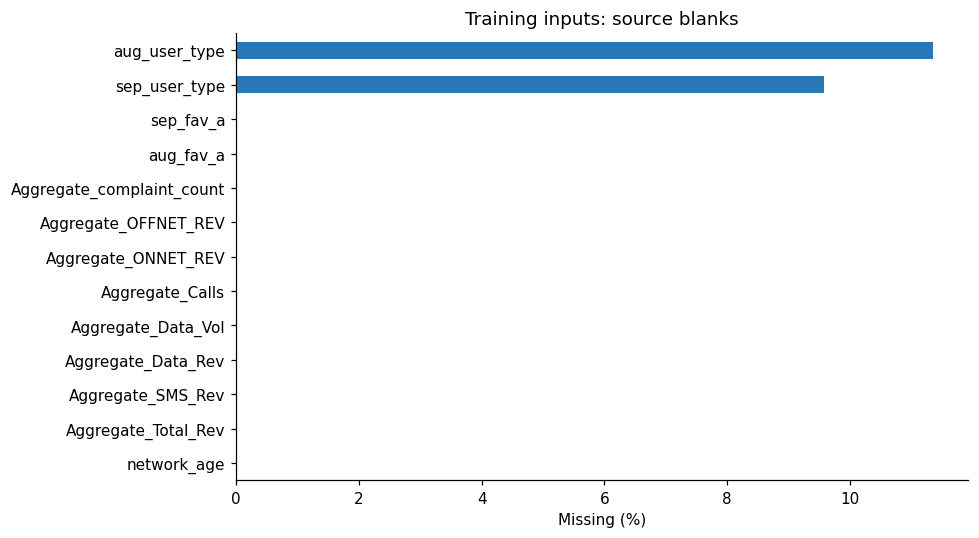

In [7]:
missing = eda[FEATURES].isna().sum().sort_values()
sample(
    eda[["aug_user_type", "sep_user_type"]].assign(aug_missing=eda.aug_user_type.isna().astype(int))
)
mt = pd.DataFrame(
    {"field": missing.index, "missing": missing.values, "percent": 100 * missing.values / M}
)
table(mt)
fig, ax = plt.subplots(figsize=(9, 5))
(100 * missing / M).plot.barh(ax=ax, color="#2878b5")
ax.set(xlabel="Missing (%)", title="Training inputs: source blanks")
finish("missing")
mt.to_csv(OUT / "missing_summary.csv", index=False)


**Ví dụ tính từ dữ liệu:**

aug_user_type: 159/1400×100=11,36%

**Nhận xét:** Tập học có 293 ô trống, trong đó loại dịch vụ tháng 8 thiếu nhiều nhất: 159/1400 hồ sơ, tương đương 11,36%. Bài sẽ giữ các khách này và tạo nhóm “chưa có thông tin” cho ô trống.

### 4.2. Các ô thiếu có nằm cùng hồ sơ không?
Một khách có thể thiếu nhiều thông tin. Bởi vậy, **tổng số ô thiếu** khác với **số hồ sơ có ô thiếu**.

Hình dưới hiển thị toàn bộ **1400 hồ sơ của tập học** và **13 cột đầu vào**. Mỗi cột dọc ứng với một hồ sơ; mỗi hàng ngang ứng với một thuộc tính. Mỗi ô có màu cho biết thông tin đó bị thiếu hay còn đầy đủ; đưa chuột vào để xem dòng và tên cột. Bảng 5 hàng minh họa cách đếm trường thiếu trong từng hồ sơ. Do có nhiều hồ sơ, các cột có thể trông rất hẹp. Có thể phóng to và kéo chọn vùng trong biểu đồ HTML để xem rõ các ô. Hình giúp thấy thiếu ở đâu, chưa giải thích được vì sao thiếu.

Class,missing_fields
0,0
1,0
1,0
1,0
1,0


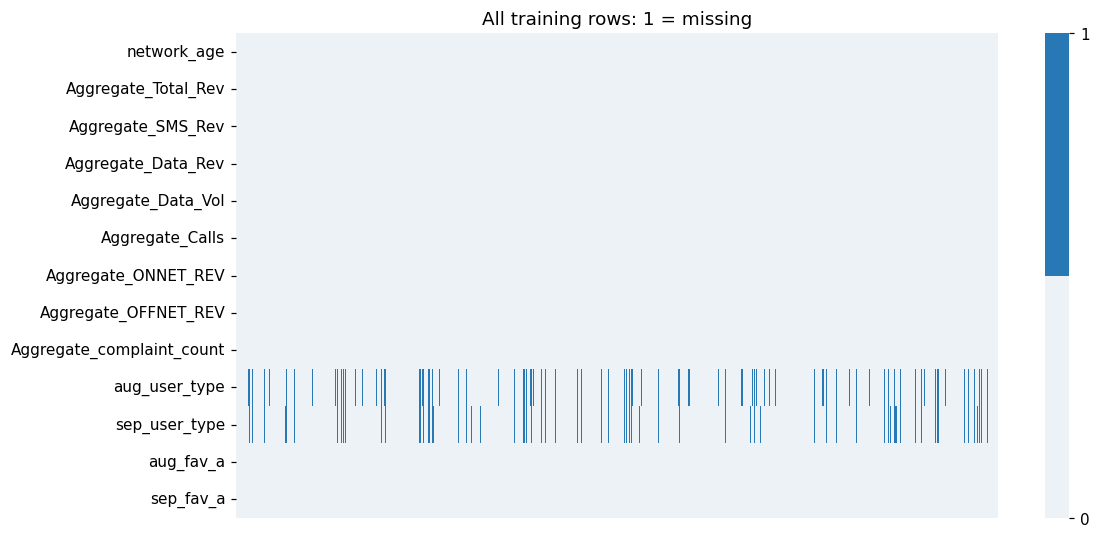

In [8]:
sample(eda[["Class"]].assign(missing_fields=eda[FEATURES].isna().sum(axis=1)))
any_missing = eda[FEATURES].isna().any(axis=1)
heat = eda[FEATURES].isna().T.astype(int)
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(heat, cmap=["#edf2f7", "#2878b5"], xticklabels=False, cbar_kws={"ticks": [0, 1]}, ax=ax)
ax.set_title("All training rows: 1 = missing")
finish("missing_pattern")


**Ví dụ tính từ dữ liệu:**

At least one missing input: 181/1400=12,93%

**Nhận xét:** Có 181/1400 hồ sơ tập học thiếu ít nhất một thông tin. Con số này nhỏ hơn 293 ô trống vì một hồ sơ có thể thiếu nhiều cột. Thiếu tên nhóm không có nghĩa mọi thông tin khác của khách đều bỏ đi.

## 5. Khách hàng có mức sử dụng dịch vụ như thế nào?
Ta xem riêng 9 cột số để biết giá trị thường gặp, mức chênh lệch và những hồ sơ khác biệt.

**Cách đọc bảng thống kê:**

| Chỉ số | Ý nghĩa |
|---|---|
| `count` | Số giá trị có dữ liệu, không tính ô thiếu. |
| `mean` | Trung bình: tổng các giá trị chia cho số giá trị có dữ liệu. |
| `std` | Độ lệch chuẩn: cho biết các giá trị phân tán quanh trung bình nhiều hay ít. |
| `min` | Giá trị nhỏ nhất. |
| `25%` — Q1 | Mốc phân vị 25% khi sắp xếp các giá trị từ nhỏ đến lớn. |
| `50%` — trung vị | Giá trị ở giữa sau khi sắp xếp; nếu có số lượng giá trị chẵn, lấy trung bình hai giá trị ở giữa. |
| `75%` — Q3 | Mốc phân vị 75% khi sắp xếp các giá trị từ nhỏ đến lớn. |
| `max` | Giá trị lớn nhất. |

Q1 và Q3 bao quanh nửa số quan sát ở giữa theo thứ tự đã sắp xếp. Khoảng cách Q3 − Q1 được gọi là IQR và sẽ dùng ở phần 5.2.

Các biểu đồ cột theo khoảng bên dưới được gọi là **histogram**: trục ngang là khoảng giá trị, trục dọc là số hồ sơ trong khoảng. Bài chia thành 30 khoảng. Ký hiệu [a,b) nghĩa là nhận a nhưng chưa nhận b; riêng khoảng cuối nhận cả b. Các số âm nguồn vẫn xuất hiện để người đọc thấy vấn đề trước khi xử lý.

In [9]:
table(eda[NUM].describe().T.reset_index(names="field"))
eda[NUM].describe().T.to_csv(OUT / "numeric_summary.csv")


field,count,mean,std,min,25%,50%,75%,max
network_age,1400,"1457,48","1312,05","-8,00","278,75","1142,00","2261,75","5451,00"
Aggregate_Total_Rev,1400,"894,70","1179,93","4,91","256,21","619,22","1219,05","24438,83"
Aggregate_SMS_Rev,1400,"31,52","58,99","0,00","3,27","14,34","34,17","665,00"
Aggregate_Data_Rev,1400,"53,56","248,81","0,00","1,25","13,75","51,25","8295,00"
Aggregate_Data_Vol,1400,"2953193,59","9449406,14","0,10","3237,21","176029,80","1562888,06","155031212,80"
Aggregate_Calls,1400,"246,77","378,38","1,00","25,00","104,00","339,00","5727,00"
Aggregate_ONNET_REV,1400,"7438,86","17595,08","0,00","114,00","1976,50","7855,50","381174,00"
Aggregate_OFFNET_REV,1400,"16278,83","34067,38","0,00","1458,00","5097,50","16176,00","431440,00"
Aggregate_complaint_count,1400,"1,93","2,36","1,00","1,00","1,00","2,00","49,00"


### 5.1.1. Thời gian đã sử dụng dịch vụ (`network_age`)
Hình này cho biết khách hàng thường có thời gian đã sử dụng dịch vụ ở mức nào. Mỗi cột đếm số hồ sơ thuộc một khoảng giá trị; cột cao hơn nghĩa là nhiều hồ sơ hơn.

Bảng dưới chọn 5 hồ sơ nằm trong khoảng đông nhất để minh họa. Con số trên cột được tính từ **mọi hồ sơ trong khoảng**, không phải chỉ 5 hàng này. Các cột lớn/nhỏ giúp nhìn mức phổ biến và những giá trị ít gặp; chưa nói được ai đã rời dịch vụ.

network_age,Class
149,0
117,1
155,1
147,0
104,0


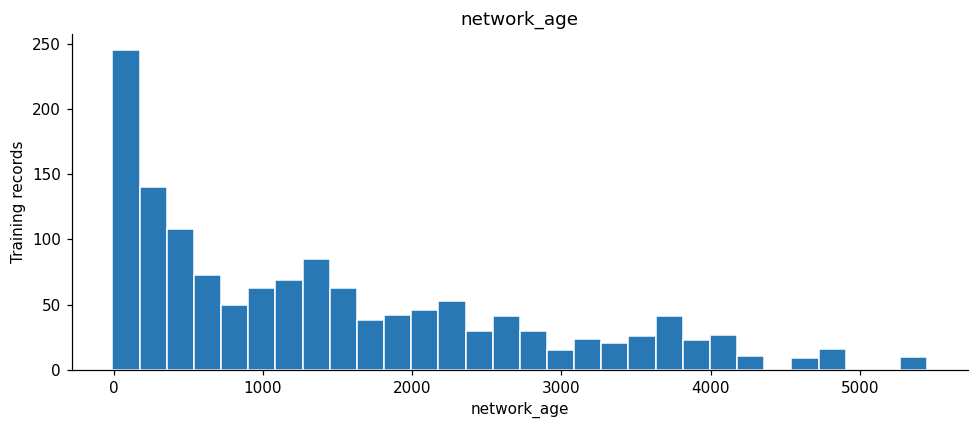

In [10]:
field = "network_age"
v = eda[field].dropna()
counts, edges = np.histogram(v, bins=30)
j = int(counts.argmax())
a, b = edges[j : j + 2]
mask = eda[field].ge(a) & (eda[field].le(b) if j == 29 else eda[field].lt(b))
sample(eda.loc[mask, [field, "Class"]])
right = "]" if j == 29 else ")"
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(v, bins=edges, color="#2878b5", edgecolor="white")
ax.set(xlabel=field, ylabel="Training records", title=field)
finish("hist_network_age")


**Ví dụ tính từ dữ liệu:**

Bin [-8,00;173,97): 245/1400=17,50%

**Nhận xét:** Trong 1400 hồ sơ tập học, khoảng từ -8,00 đến 173,97 chứa nhiều hồ sơ nhất: 245 (17,50%). Trung bình là 1457,48, còn giá trị ở giữa (trung vị) là 1142,00. Có 3 thời gian âm cần xử lý trước khi huấn luyện.

### 5.1.2. Doanh thu tổng (`Aggregate_Total_Rev`)
Hình này cho biết khách hàng thường có doanh thu tổng ở mức nào. Mỗi cột đếm số hồ sơ thuộc một khoảng giá trị; cột cao hơn nghĩa là nhiều hồ sơ hơn.

Bảng dưới chọn 5 hồ sơ nằm trong khoảng đông nhất để minh họa. Con số trên cột được tính từ **mọi hồ sơ trong khoảng**, không phải chỉ 5 hàng này. Các cột lớn/nhỏ giúp nhìn mức phổ biến và những giá trị ít gặp; chưa nói được ai đã rời dịch vụ.

Aggregate_Total_Rev,Class
"152,45",0
"135,38",1
"682,79",1
"155,57",1
"242,17",1


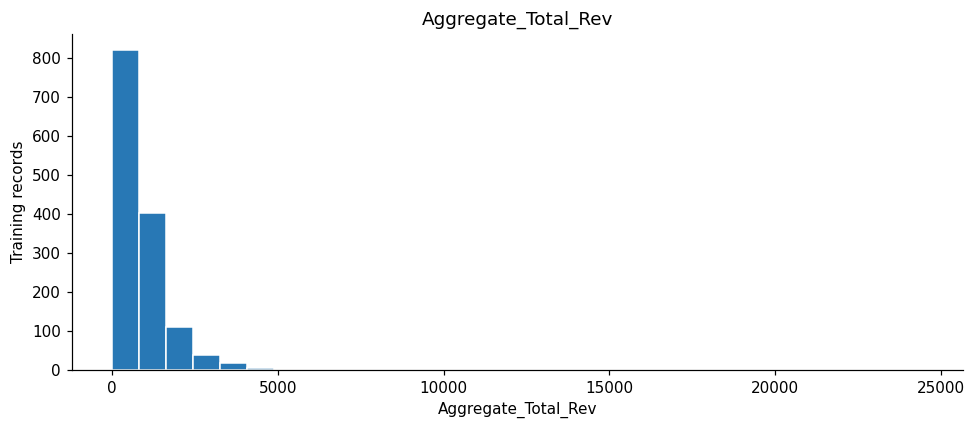

In [11]:
field = "Aggregate_Total_Rev"
v = eda[field].dropna()
counts, edges = np.histogram(v, bins=30)
j = int(counts.argmax())
a, b = edges[j : j + 2]
mask = eda[field].ge(a) & (eda[field].le(b) if j == 29 else eda[field].lt(b))
sample(eda.loc[mask, [field, "Class"]])
right = "]" if j == 29 else ")"
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(v, bins=edges, color="#2878b5", edgecolor="white")
ax.set(xlabel=field, ylabel="Training records", title=field)
finish("hist_Aggregate_Total_Rev")


**Ví dụ tính từ dữ liệu:**

Bin [4,91;819,37): 819/1400=58,50%

**Nhận xét:** Trong 1400 hồ sơ tập học, khoảng từ 4,91 đến 819,37 chứa nhiều hồ sơ nhất: 819 (58,50%). Trung bình là 894,70, còn giá trị ở giữa (trung vị) là 619,22. Một số giá trị lớn kéo trung bình lên cao hơn trung vị. Vì vậy xem thêm cả hai con số sẽ dễ hiểu mức thông thường hơn chỉ nhìn trung bình.

### 5.1.3. Doanh thu từ tin nhắn (`Aggregate_SMS_Rev`)
Hình này cho biết khách hàng thường có doanh thu từ tin nhắn ở mức nào. Mỗi cột đếm số hồ sơ thuộc một khoảng giá trị; cột cao hơn nghĩa là nhiều hồ sơ hơn.

Bảng dưới chọn 5 hồ sơ nằm trong khoảng đông nhất để minh họa. Con số trên cột được tính từ **mọi hồ sơ trong khoảng**, không phải chỉ 5 hàng này. Các cột lớn/nhỏ giúp nhìn mức phổ biến và những giá trị ít gặp; chưa nói được ai đã rời dịch vụ.

Aggregate_SMS_Rev,Class
"7,73",0
"1,75",1
"19,70",1
"3,50",1
"3,50",1


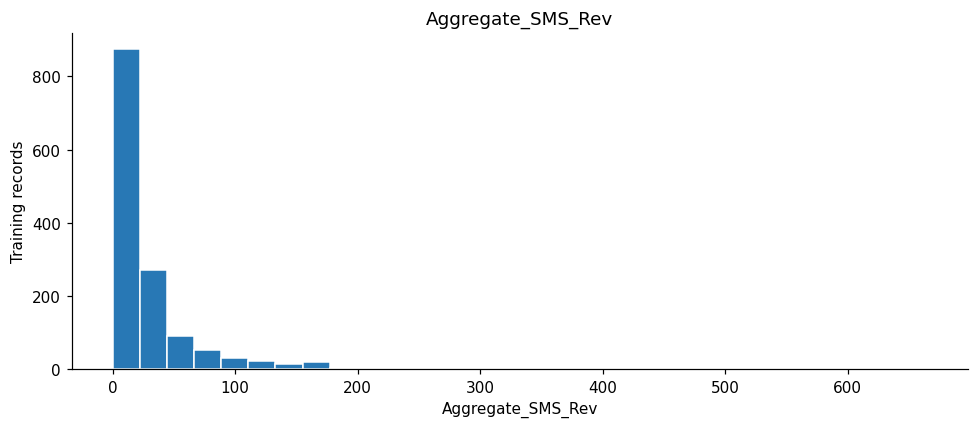

In [12]:
field = "Aggregate_SMS_Rev"
v = eda[field].dropna()
counts, edges = np.histogram(v, bins=30)
j = int(counts.argmax())
a, b = edges[j : j + 2]
mask = eda[field].ge(a) & (eda[field].le(b) if j == 29 else eda[field].lt(b))
sample(eda.loc[mask, [field, "Class"]])
right = "]" if j == 29 else ")"
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(v, bins=edges, color="#2878b5", edgecolor="white")
ax.set(xlabel=field, ylabel="Training records", title=field)
finish("hist_Aggregate_SMS_Rev")


**Ví dụ tính từ dữ liệu:**

Bin [0,00;22,17): 875/1400=62,50%

**Nhận xét:** Trong 1400 hồ sơ tập học, khoảng từ 0,00 đến 22,17 chứa nhiều hồ sơ nhất: 875 (62,50%). Trung bình là 31,52, còn giá trị ở giữa (trung vị) là 14,34. Một số giá trị lớn kéo trung bình lên cao hơn trung vị. Vì vậy xem thêm cả hai con số sẽ dễ hiểu mức thông thường hơn chỉ nhìn trung bình.

### 5.1.4. Doanh thu từ dịch vụ dữ liệu (`Aggregate_Data_Rev`)
Hình này cho biết khách hàng thường có doanh thu từ dịch vụ dữ liệu ở mức nào. Mỗi cột đếm số hồ sơ thuộc một khoảng giá trị; cột cao hơn nghĩa là nhiều hồ sơ hơn.

Bảng dưới chọn 5 hồ sơ nằm trong khoảng đông nhất để minh họa. Con số trên cột được tính từ **mọi hồ sơ trong khoảng**, không phải chỉ 5 hàng này. Các cột lớn/nhỏ giúp nhìn mức phổ biến và những giá trị ít gặp; chưa nói được ai đã rời dịch vụ.

Aggregate_Data_Rev,Class
"1,25",0
"0,00",1
"20,00",1
"81,25",1
"56,25",1


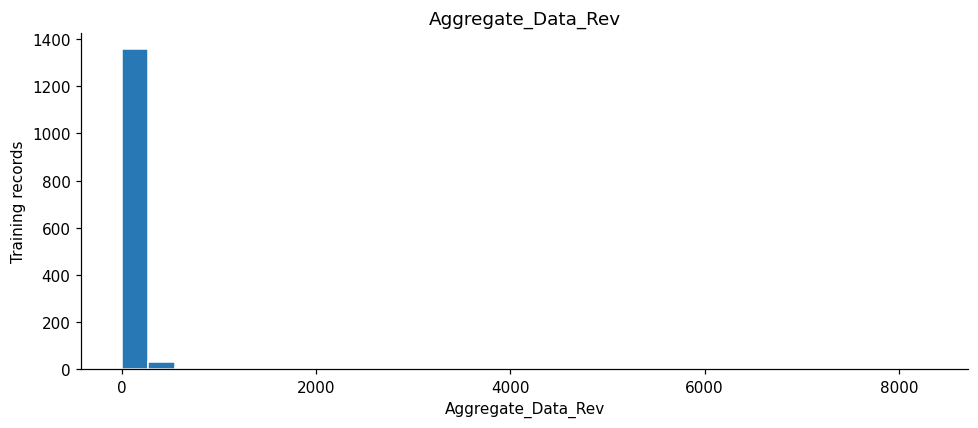

In [13]:
field = "Aggregate_Data_Rev"
v = eda[field].dropna()
counts, edges = np.histogram(v, bins=30)
j = int(counts.argmax())
a, b = edges[j : j + 2]
mask = eda[field].ge(a) & (eda[field].le(b) if j == 29 else eda[field].lt(b))
sample(eda.loc[mask, [field, "Class"]])
right = "]" if j == 29 else ")"
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(v, bins=edges, color="#2878b5", edgecolor="white")
ax.set(xlabel=field, ylabel="Training records", title=field)
finish("hist_Aggregate_Data_Rev")


**Ví dụ tính từ dữ liệu:**

Bin [0,00;276,50): 1359/1400=97,07%

**Nhận xét:** Trong 1400 hồ sơ tập học, khoảng từ 0,00 đến 276,50 chứa nhiều hồ sơ nhất: 1359 (97,07%). Trung bình là 53,56, còn giá trị ở giữa (trung vị) là 13,75. Một số giá trị lớn kéo trung bình lên cao hơn trung vị. Vì vậy xem thêm cả hai con số sẽ dễ hiểu mức thông thường hơn chỉ nhìn trung bình.

### 5.1.5. Dung lượng dữ liệu đã dùng (`Aggregate_Data_Vol`)
Hình này cho biết khách hàng thường có dung lượng dữ liệu đã dùng ở mức nào. Mỗi cột đếm số hồ sơ thuộc một khoảng giá trị; cột cao hơn nghĩa là nhiều hồ sơ hơn.

Bảng dưới chọn 5 hồ sơ nằm trong khoảng đông nhất để minh họa. Con số trên cột được tính từ **mọi hồ sơ trong khoảng**, không phải chỉ 5 hàng này. Các cột lớn/nhỏ giúp nhìn mức phổ biến và những giá trị ít gặp; chưa nói được ai đã rời dịch vụ.

Aggregate_Data_Vol,Class
"1,92",0
"365237,51",1
"692988,93",1
"109394,71",1
"26,14",1


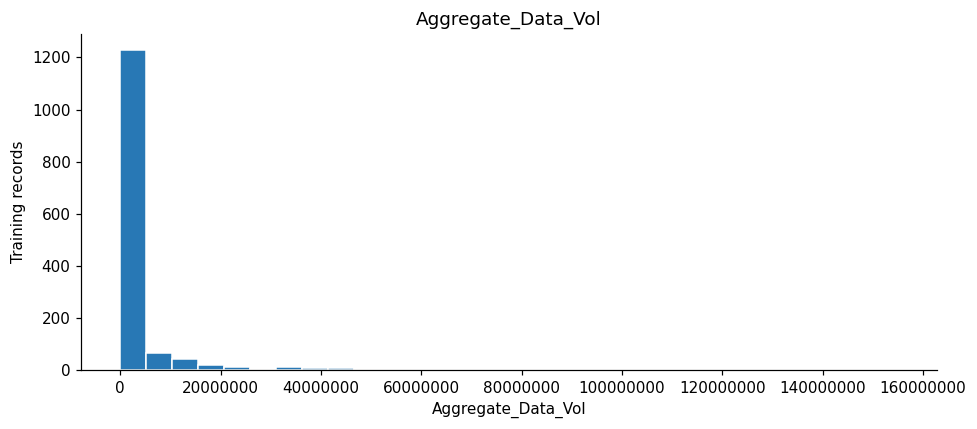

In [14]:
field = "Aggregate_Data_Vol"
v = eda[field].dropna()
counts, edges = np.histogram(v, bins=30)
j = int(counts.argmax())
a, b = edges[j : j + 2]
mask = eda[field].ge(a) & (eda[field].le(b) if j == 29 else eda[field].lt(b))
sample(eda.loc[mask, [field, "Class"]])
right = "]" if j == 29 else ")"
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(v, bins=edges, color="#2878b5", edgecolor="white")
ax.set(xlabel=field, ylabel="Training records", title=field)
finish("hist_Aggregate_Data_Vol")


**Ví dụ tính từ dữ liệu:**

Bin [0,10;5167707,19): 1228/1400=87,71%

**Nhận xét:** Trong 1400 hồ sơ tập học, khoảng từ 0,10 đến 5167707,19 chứa nhiều hồ sơ nhất: 1228 (87,71%). Trung bình là 2953193,59, còn giá trị ở giữa (trung vị) là 176029,80. Một số giá trị lớn kéo trung bình lên cao hơn trung vị. Vì vậy xem thêm cả hai con số sẽ dễ hiểu mức thông thường hơn chỉ nhìn trung bình.

### 5.1.6. Số cuộc gọi (`Aggregate_Calls`)
Hình này cho biết khách hàng thường có số cuộc gọi ở mức nào. Mỗi cột đếm số hồ sơ thuộc một khoảng giá trị; cột cao hơn nghĩa là nhiều hồ sơ hơn.

Bảng dưới chọn 5 hồ sơ nằm trong khoảng đông nhất để minh họa. Con số trên cột được tính từ **mọi hồ sơ trong khoảng**, không phải chỉ 5 hàng này. Các cột lớn/nhỏ giúp nhìn mức phổ biến và những giá trị ít gặp; chưa nói được ai đã rời dịch vụ.

Aggregate_Calls,Class
44,0
11,1
27,1
3,1
20,1


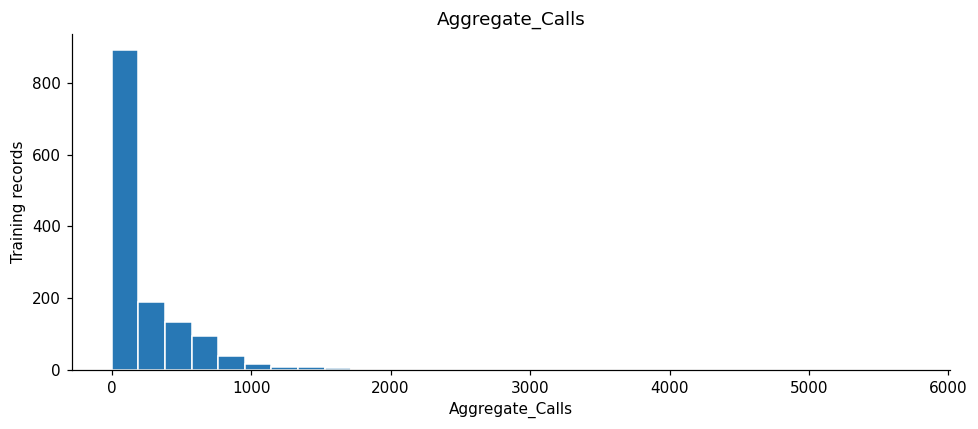

In [15]:
field = "Aggregate_Calls"
v = eda[field].dropna()
counts, edges = np.histogram(v, bins=30)
j = int(counts.argmax())
a, b = edges[j : j + 2]
mask = eda[field].ge(a) & (eda[field].le(b) if j == 29 else eda[field].lt(b))
sample(eda.loc[mask, [field, "Class"]])
right = "]" if j == 29 else ")"
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(v, bins=edges, color="#2878b5", edgecolor="white")
ax.set(xlabel=field, ylabel="Training records", title=field)
finish("hist_Aggregate_Calls")


**Ví dụ tính từ dữ liệu:**

Bin [1,00;191,87): 891/1400=63,64%

**Nhận xét:** Trong 1400 hồ sơ tập học, khoảng từ 1,00 đến 191,87 chứa nhiều hồ sơ nhất: 891 (63,64%). Trung bình là 246,77, còn giá trị ở giữa (trung vị) là 104,00. Một số giá trị lớn kéo trung bình lên cao hơn trung vị. Vì vậy xem thêm cả hai con số sẽ dễ hiểu mức thông thường hơn chỉ nhìn trung bình.

### 5.1.7. Doanh thu nội mạng (`Aggregate_ONNET_REV`)
Hình này cho biết khách hàng thường có doanh thu nội mạng ở mức nào. Mỗi cột đếm số hồ sơ thuộc một khoảng giá trị; cột cao hơn nghĩa là nhiều hồ sơ hơn.

Bảng dưới chọn 5 hồ sơ nằm trong khoảng đông nhất để minh họa. Con số trên cột được tính từ **mọi hồ sơ trong khoảng**, không phải chỉ 5 hàng này. Các cột lớn/nhỏ giúp nhìn mức phổ biến và những giá trị ít gặp; chưa nói được ai đã rời dịch vụ.

Aggregate_ONNET_REV,Class
1464,0
24,1
846,1
0,1
2900,1


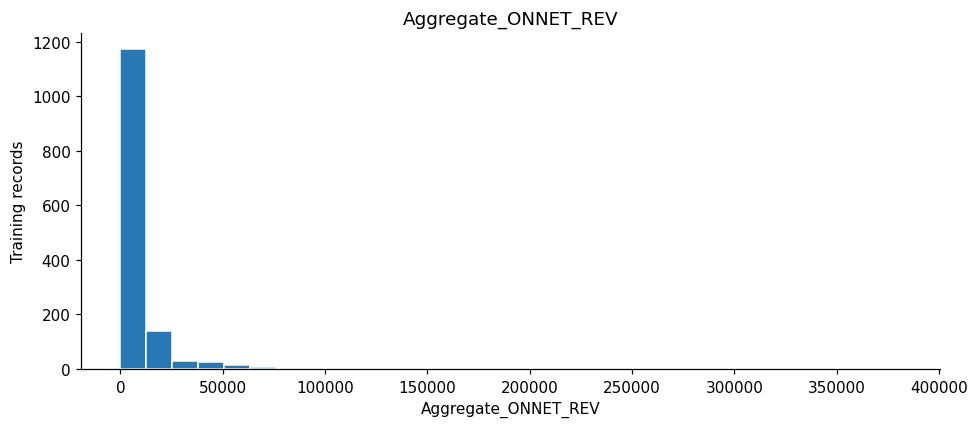

In [16]:
field = "Aggregate_ONNET_REV"
v = eda[field].dropna()
counts, edges = np.histogram(v, bins=30)
j = int(counts.argmax())
a, b = edges[j : j + 2]
mask = eda[field].ge(a) & (eda[field].le(b) if j == 29 else eda[field].lt(b))
sample(eda.loc[mask, [field, "Class"]])
right = "]" if j == 29 else ")"
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(v, bins=edges, color="#2878b5", edgecolor="white")
ax.set(xlabel=field, ylabel="Training records", title=field)
finish("hist_Aggregate_ONNET_REV")


**Ví dụ tính từ dữ liệu:**

Bin [0,00;12705,80): 1174/1400=83,86%

**Nhận xét:** Trong 1400 hồ sơ tập học, khoảng từ 0,00 đến 12705,80 chứa nhiều hồ sơ nhất: 1174 (83,86%). Trung bình là 7438,86, còn giá trị ở giữa (trung vị) là 1976,50. Một số giá trị lớn kéo trung bình lên cao hơn trung vị. Vì vậy xem thêm cả hai con số sẽ dễ hiểu mức thông thường hơn chỉ nhìn trung bình.

### 5.1.8. Doanh thu ngoại mạng (`Aggregate_OFFNET_REV`)
Hình này cho biết khách hàng thường có doanh thu ngoại mạng ở mức nào. Mỗi cột đếm số hồ sơ thuộc một khoảng giá trị; cột cao hơn nghĩa là nhiều hồ sơ hơn.

Bảng dưới chọn 5 hồ sơ nằm trong khoảng đông nhất để minh họa. Con số trên cột được tính từ **mọi hồ sơ trong khoảng**, không phải chỉ 5 hàng này. Các cột lớn/nhỏ giúp nhìn mức phổ biến và những giá trị ít gặp; chưa nói được ai đã rời dịch vụ.

Aggregate_OFFNET_REV,Class
2206,0
4893,1
10522,1
537,1
4493,1


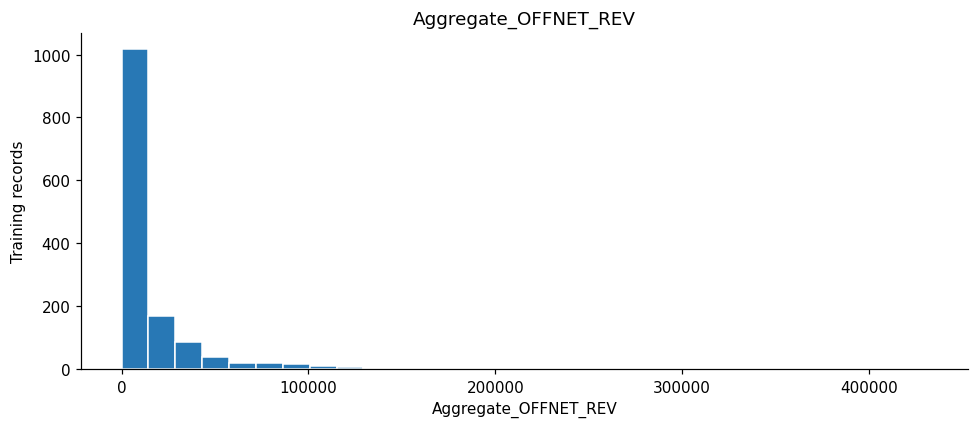

In [17]:
field = "Aggregate_OFFNET_REV"
v = eda[field].dropna()
counts, edges = np.histogram(v, bins=30)
j = int(counts.argmax())
a, b = edges[j : j + 2]
mask = eda[field].ge(a) & (eda[field].le(b) if j == 29 else eda[field].lt(b))
sample(eda.loc[mask, [field, "Class"]])
right = "]" if j == 29 else ")"
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(v, bins=edges, color="#2878b5", edgecolor="white")
ax.set(xlabel=field, ylabel="Training records", title=field)
finish("hist_Aggregate_OFFNET_REV")


**Ví dụ tính từ dữ liệu:**

Bin [0,00;14381,33): 1018/1400=72,71%

**Nhận xét:** Trong 1400 hồ sơ tập học, khoảng từ 0,00 đến 14381,33 chứa nhiều hồ sơ nhất: 1018 (72,71%). Trung bình là 16278,83, còn giá trị ở giữa (trung vị) là 5097,50. Một số giá trị lớn kéo trung bình lên cao hơn trung vị. Vì vậy xem thêm cả hai con số sẽ dễ hiểu mức thông thường hơn chỉ nhìn trung bình.

### 5.1.9. Số lần khiếu nại (`Aggregate_complaint_count`)
Hình này cho biết khách hàng thường có số lần khiếu nại ở mức nào. Mỗi cột đếm số hồ sơ thuộc một khoảng giá trị; cột cao hơn nghĩa là nhiều hồ sơ hơn.

Bảng dưới chọn 5 hồ sơ nằm trong khoảng đông nhất để minh họa. Con số trên cột được tính từ **mọi hồ sơ trong khoảng**, không phải chỉ 5 hàng này. Các cột lớn/nhỏ giúp nhìn mức phổ biến và những giá trị ít gặp; chưa nói được ai đã rời dịch vụ.

Aggregate_complaint_count,Class
2,0
1,1
2,1
1,1
2,1


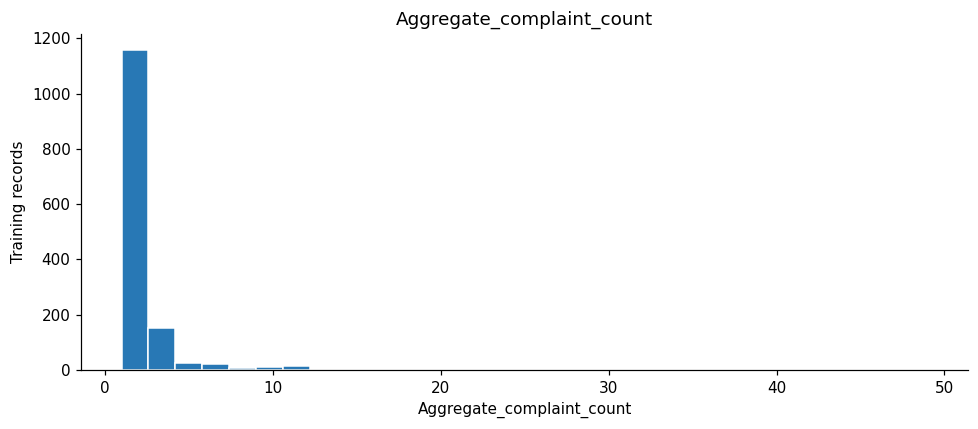

In [18]:
field = "Aggregate_complaint_count"
v = eda[field].dropna()
counts, edges = np.histogram(v, bins=30)
j = int(counts.argmax())
a, b = edges[j : j + 2]
mask = eda[field].ge(a) & (eda[field].le(b) if j == 29 else eda[field].lt(b))
sample(eda.loc[mask, [field, "Class"]])
right = "]" if j == 29 else ")"
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(v, bins=edges, color="#2878b5", edgecolor="white")
ax.set(xlabel=field, ylabel="Training records", title=field)
finish("hist_Aggregate_complaint_count")


**Ví dụ tính từ dữ liệu:**

Bin [1,00;2,60): 1157/1400=82,64%

**Nhận xét:** Trong 1400 hồ sơ tập học, khoảng từ 1,00 đến 2,60 chứa nhiều hồ sơ nhất: 1157 (82,64%). Trung bình là 1,93, còn giá trị ở giữa (trung vị) là 1,00. Một số giá trị lớn kéo trung bình lên cao hơn trung vị. Vì vậy xem thêm cả hai con số sẽ dễ hiểu mức thông thường hơn chỉ nhìn trung bình.

### 5.2. Phát hiện ngoại lệ bằng IQR — Outlier Detection
Sau khi xem phân bố của từng cột, ta cần biết **có bao nhiêu hồ sơ có giá trị cách xa phần lớn dữ liệu**. Ta dùng cùng một quy tắc IQR cho cả 9 cột số để có bảng tổng hợp dễ so sánh.

**Cách tính:** sắp xếp các giá trị có dữ liệu của một cột. Q1 là mốc 25%, Q3 là mốc 75%; khoảng giữa hai mốc chứa nửa số giá trị ở giữa. Tính IQR = Q3 − Q1, rồi tính hai ngưỡng:

- Ngưỡng dưới = Q1 − 1,50 × IQR.
- Ngưỡng trên = Q3 + 1,50 × IQR.
- Đánh dấu giá trị nhỏ hơn ngưỡng dưới hoặc lớn hơn ngưỡng trên.
- Tỷ lệ bị đánh dấu = số hồ sơ bị đánh dấu / số hồ sơ có dữ liệu ở cột đó × 100.

Code trước tiên cho xem 5 hồ sơ doanh thu, gồm 2 hồ sơ ngoài ngưỡng và 3 hồ sơ trong ngưỡng, cùng một phép thế số. Đây là các ví dụ được chọn để đối chiếu hai trường hợp, không đại diện cho tỷ lệ của toàn bộ dữ liệu. Sau đó là bảng kết quả cho **đủ 9 cột số**, tính từ toàn bộ tập học.

**Cách đọc hình phát hiện ngoại lệ:** mỗi ô là boxplot của một thuộc tính và có thang giá trị riêng. Hộp kéo từ Q1 đến Q3, vạch trong hộp là trung vị. Hai râu kéo đến giá trị thực xa nhất còn nằm trong ngưỡng IQR; râu không nhất thiết trùng ngưỡng. Các chấm đỏ ngoài râu là ngoại lệ theo quy tắc này. Hai đường cam nét đứt đánh dấu ngưỡng dưới và trên để đối chiếu với bảng. Dòng chú thích cho biết số và tỷ lệ ngoại lệ.

Hình giúp thấy **ngoại lệ nằm ở phía giá trị nhỏ hay lớn và cách xa vùng giữa thế nào**. Không so trực tiếp độ cao giữa các ô vì các thuộc tính có đơn vị khác nhau. Nếu vài giá trị rất lớn làm hộp trông nhỏ, hãy phóng to từng ô trong bản HTML để xem vùng giữa rõ hơn.

**Cách hiểu:** IQR chỉ giúp chọn những giá trị cần xem kỹ; nó không chứng minh dữ liệu sai. Bài giữ các hồ sơ này. Riêng thời gian sử dụng âm đã được kiểm tra bằng ý nghĩa của thuộc tính ở phần 2.2 và có cách xử lý riêng.

source_row_id,Aggregate_Total_Rev,IQR_flag
1449,"3124,07",True
1795,"2916,79",True
1113,"152,45",False
1531,"135,38",False
1444,"1367,68",False


field,observed,Q1,Q3,IQR,lower_threshold,upper_threshold,flagged_count,flagged_percent
network_age,1400,"278,75","2261,75","1983,00","-2695,75","5236,25",10,"0,71"
Aggregate_Total_Rev,1400,"256,21","1219,05","962,83","-1188,04","2663,30",56,"4,00"
Aggregate_SMS_Rev,1400,"3,27","34,17","30,91","-43,09","80,53",129,"9,21"
Aggregate_Data_Rev,1400,"1,25","51,25","50,00","-73,75","126,25",133,"9,50"
Aggregate_Data_Vol,1400,"3237,21","1562888,06","1559650,84","-2336239,06","3902364,32",202,"14,43"
Aggregate_Calls,1400,"25,00","339,00","314,00","-446,00","810,00",81,"5,79"
Aggregate_ONNET_REV,1400,"114,00","7855,50","7741,50","-11498,25","19467,75",133,"9,50"
Aggregate_OFFNET_REV,1400,"1458,00","16176,00","14718,00","-20619,00","38253,00",148,"10,57"
Aggregate_complaint_count,1400,"1,00","2,00","1,00","-0,50","3,50",136,"9,71"


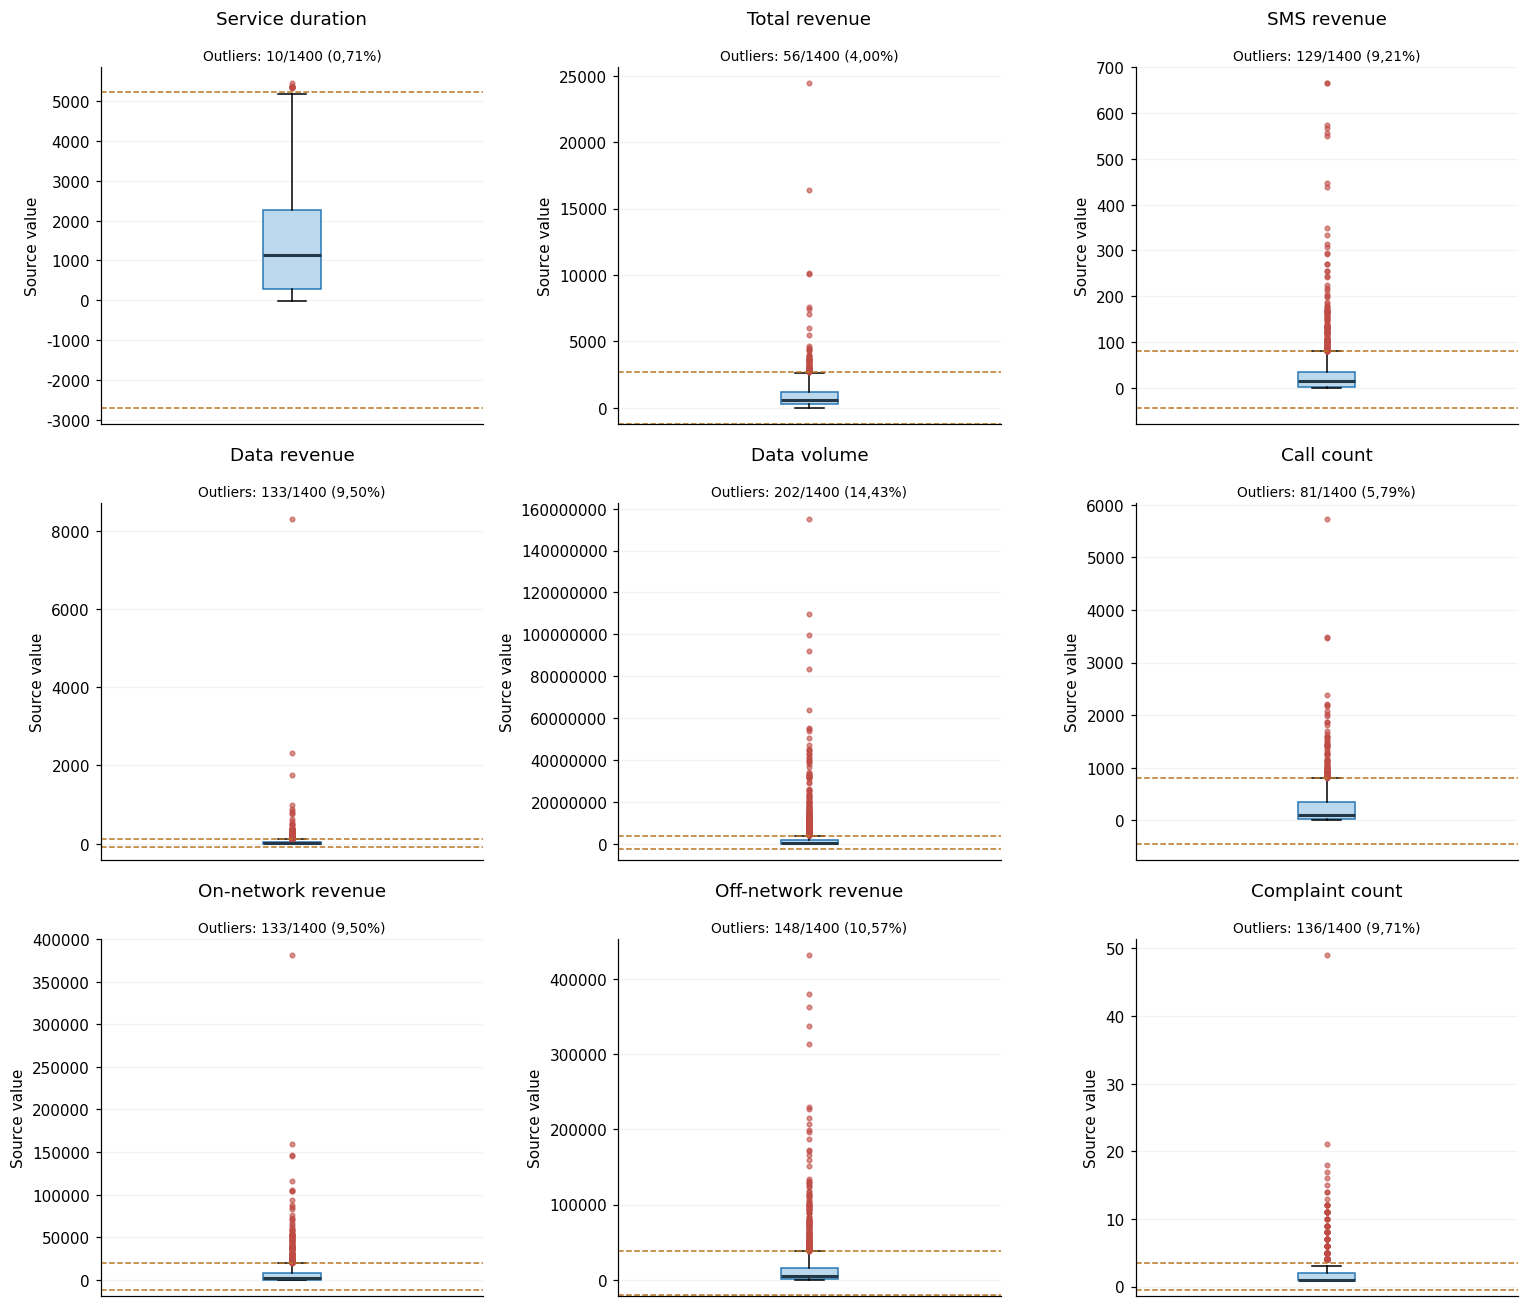

In [19]:
iqr_rows = []
for field in NUM:
    values = eda[field].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flags = (values < lower) | (values > upper)
    iqr_rows.append(
        {
            "field": field,
            "observed": len(values),
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "lower_threshold": lower,
            "upper_threshold": upper,
            "flagged_count": int(flags.sum()),
            "flagged_percent": 100 * flags.mean(),
        }
    )
outlier_summary = pd.DataFrame(iqr_rows)
revenue_rule = outlier_summary.set_index("field").loc["Aggregate_Total_Rev"]
revenue_values = eda.Aggregate_Total_Rev
revenue_flags = (revenue_values < revenue_rule.lower_threshold) | (
    revenue_values > revenue_rule.upper_threshold
)
example_ids = list(revenue_flags[revenue_flags].head(2).index) + list(
    revenue_flags[~revenue_flags].head(3).index
)
examples = eda.loc[example_ids, ["Aggregate_Total_Rev"]].copy()
examples["IQR_flag"] = revenue_flags.loc[example_ids]
table(examples.reset_index(names="source_row_id"))
table(outlier_summary)
outlier_summary.to_csv(OUT / "outlier_summary.csv", index=False)
first_value = examples.Aggregate_Total_Rev.iloc[0]
short_names = [
    "Service duration",
    "Total revenue",
    "SMS revenue",
    "Data revenue",
    "Data volume",
    "Call count",
    "On-network revenue",
    "Off-network revenue",
    "Complaint count",
]
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for ax, field, title in zip(axes.flat, NUM, short_names):
    values = eda[field].dropna()
    rule = outlier_summary.set_index("field").loc[field]
    ax.boxplot(
        values,
        vert=True,
        whis=1.5,
        patch_artist=True,
        boxprops={"facecolor": "#bcd8ec", "edgecolor": "#2878b5"},
        medianprops={"color": "#243746", "linewidth": 2},
        flierprops={
            "marker": "o",
            "markersize": 3,
            "markerfacecolor": "#bf4b45",
            "markeredgecolor": "#bf4b45",
            "alpha": 0.6,
        },
    )
    ax.axhline(rule.lower_threshold, color="#b97722", linestyle="--", linewidth=1)
    ax.axhline(rule.upper_threshold, color="#b97722", linestyle="--", linewidth=1)
    ax.set_title(title, pad=28)
    ax.text(
        0.5,
        1.02,
        f"Outliers: {int(rule.flagged_count)}/{int(rule.observed)} ({rule.flagged_percent:.2f}%)",
        transform=ax.transAxes,
        ha="center",
        fontsize=9,
    )
    ax.set_xticks([])
    ax.set_ylabel("Source value")
    ax.grid(axis="y", alpha=0.15)
finish("outliers")
highest = outlier_summary.sort_values("flagged_percent").iloc[-1]


**Ví dụ tính từ dữ liệu:**

IQR = 1219,05 − 256,21 = 962,83; lower = 256,21 − 1,50 × 962,83 = -1188,04; upper = 1219,05 + 1,50 × 962,83 = 2663,30; flagged = 56/1400 × 100 = 4,00%

3124,07 > 2663,30: True → IQR_flag = True

**Nhận xét:** Dung lượng dữ liệu đã dùng có tỷ lệ bị đánh dấu cao nhất: 202/1400 hồ sơ (14,43%). Mỗi cột được tính ngưỡng riêng theo phân bố của nó. Đây là những giá trị cần xem kỹ, chưa phải dữ liệu sai; bài giữ các hồ sơ và chỉ xử lý riêng thời gian sử dụng âm theo ý nghĩa thuộc tính.

## 6. Khách hàng thuộc những nhóm dịch vụ nào?
Bốn cột tiếp theo chứa tên nhóm, không phải số tiền hay số lần. Ta đếm số khách theo loại dịch vụ và mạng khác thường được liên lạc ở từng tháng.

### 6.1. Loại dịch vụ tháng 8 (`aug_user_type`)
Ta đếm mỗi nhóm có bao nhiêu hồ sơ trong 1400 khách của tập học. Biểu đồ thanh ngang giúp đọc tên nhóm rõ hơn; thanh dài hơn nghĩa là nhóm đông hơn.

Bảng đầu là 5 ví dụ của nhóm đông nhất. Bảng sau mới là số lượng đầy đủ. Tỷ lệ nhóm = số hồ sơ nhóm / 1400. `Missing` là chưa có thông tin, còn `Other` là nhóm khác được ghi sẵn.

aug_user_type,Class
3G,0
3G,1
3G,1
3G,1
3G,1


category,records
3G,684
2G,295
Other,262
Missing,159


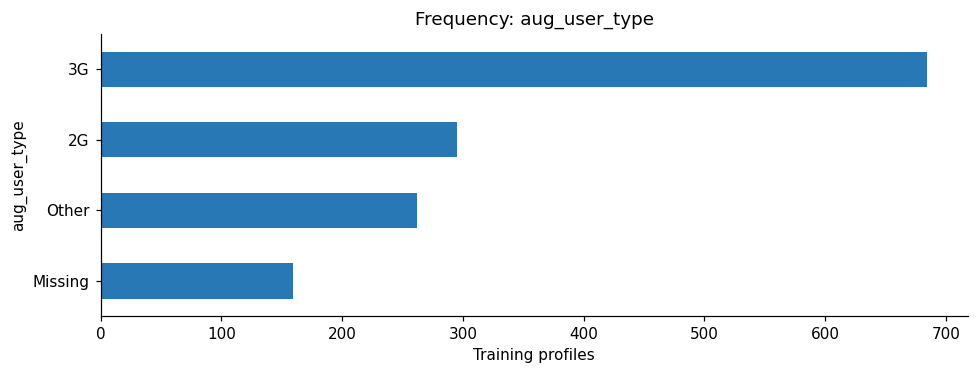

In [20]:
field = "aug_user_type"
labels = eda[field].fillna("Missing")
freq = labels.value_counts()
focus = freq.idxmax()
sample(eda.loc[labels.eq(focus), [field, "Class"]])
table(freq.rename_axis("category").reset_index(name="records"))
fig, ax = plt.subplots(figsize=(9, max(3.5, len(freq) * 0.35)))
freq.sort_values().plot.barh(ax=ax, color="#2878b5")
ax.set(xlabel="Training profiles", title="Frequency: " + field)
finish("cat_aug_user_type")


**Ví dụ tính từ dữ liệu:**

3G: 684/1400=48,86%

**Nhận xét:** Nhóm 3G có nhiều hồ sơ nhất: 684/1400, tương đương 48,86%. Hình này mới cho biết nhóm nào đông; phần 7 sẽ xem tỷ lệ đã rời dịch vụ trong từng nhóm.

### 6.2. Loại dịch vụ tháng 9 (`sep_user_type`)
Ta đếm mỗi nhóm có bao nhiêu hồ sơ trong 1400 khách của tập học. Biểu đồ thanh ngang giúp đọc tên nhóm rõ hơn; thanh dài hơn nghĩa là nhóm đông hơn.

Bảng đầu là 5 ví dụ của nhóm đông nhất. Bảng sau mới là số lượng đầy đủ. Tỷ lệ nhóm = số hồ sơ nhóm / 1400. `Missing` là chưa có thông tin, còn `Other` là nhóm khác được ghi sẵn.

sep_user_type,Class
3G,1
3G,1
3G,1
3G,1
3G,0


category,records
3G,731
2G,273
Other,262
Missing,134


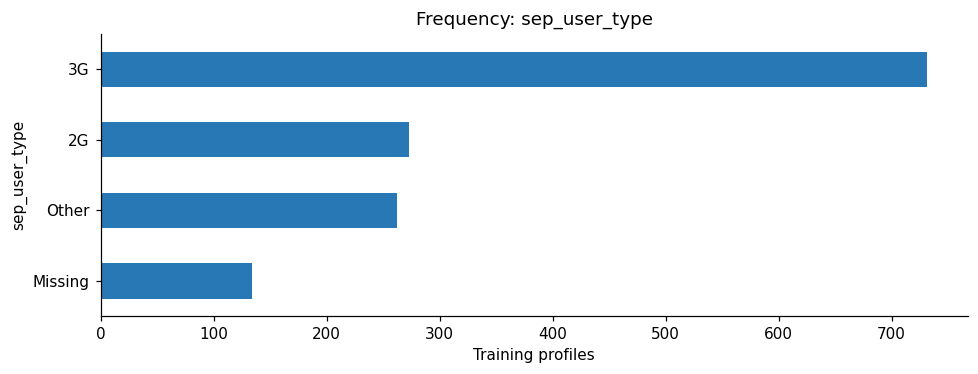

In [21]:
field = "sep_user_type"
labels = eda[field].fillna("Missing")
freq = labels.value_counts()
focus = freq.idxmax()
sample(eda.loc[labels.eq(focus), [field, "Class"]])
table(freq.rename_axis("category").reset_index(name="records"))
fig, ax = plt.subplots(figsize=(9, max(3.5, len(freq) * 0.35)))
freq.sort_values().plot.barh(ax=ax, color="#2878b5")
ax.set(xlabel="Training profiles", title="Frequency: " + field)
finish("cat_sep_user_type")


**Ví dụ tính từ dữ liệu:**

3G: 731/1400=52,21%

**Nhận xét:** Nhóm 3G có nhiều hồ sơ nhất: 731/1400, tương đương 52,21%. Hình này mới cho biết nhóm nào đông; phần 7 sẽ xem tỷ lệ đã rời dịch vụ trong từng nhóm.

### 6.3. Mạng khác được liên lạc nhiều nhất tháng 8 (`aug_fav_a`)
Ta đếm mỗi nhóm có bao nhiêu hồ sơ trong 1400 khách của tập học. Biểu đồ thanh ngang giúp đọc tên nhóm rõ hơn; thanh dài hơn nghĩa là nhóm đông hơn.

Bảng đầu là 5 ví dụ của nhóm đông nhất. Bảng sau mới là số lượng đầy đủ. Tỷ lệ nhóm = số hồ sơ nhóm / 1400. `Missing` là chưa có thông tin, còn `Other` là nhóm khác được ghi sẵn.

aug_fav_a,Class
ptcl,1
ptcl,1
ptcl,1
ptcl,1
ptcl,0


category,records
ptcl,335
ufone,314
telenor,198
mobilink,190
zong,176
warid,144
0,43


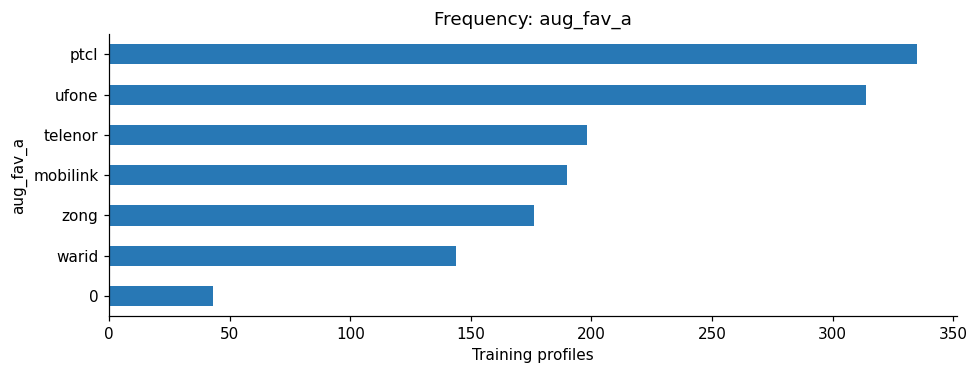

In [22]:
field = "aug_fav_a"
labels = eda[field].fillna("Missing")
freq = labels.value_counts()
focus = freq.idxmax()
sample(eda.loc[labels.eq(focus), [field, "Class"]])
table(freq.rename_axis("category").reset_index(name="records"))
fig, ax = plt.subplots(figsize=(9, max(3.5, len(freq) * 0.35)))
freq.sort_values().plot.barh(ax=ax, color="#2878b5")
ax.set(xlabel="Training profiles", title="Frequency: " + field)
finish("cat_aug_fav_a")


**Ví dụ tính từ dữ liệu:**

ptcl: 335/1400=23,93%

**Nhận xét:** Nhóm ptcl có nhiều hồ sơ nhất: 335/1400, tương đương 23,93%. Hình này mới cho biết nhóm nào đông; phần 7 sẽ xem tỷ lệ đã rời dịch vụ trong từng nhóm.

### 6.4. Mạng khác được liên lạc nhiều nhất tháng 9 (`sep_fav_a`)
Ta đếm mỗi nhóm có bao nhiêu hồ sơ trong 1400 khách của tập học. Biểu đồ thanh ngang giúp đọc tên nhóm rõ hơn; thanh dài hơn nghĩa là nhóm đông hơn.

Bảng đầu là 5 ví dụ của nhóm đông nhất. Bảng sau mới là số lượng đầy đủ. Tỷ lệ nhóm = số hồ sơ nhóm / 1400. `Missing` là chưa có thông tin, còn `Other` là nhóm khác được ghi sẵn.

sep_fav_a,Class
ufone,0
ufone,1
ufone,1
ufone,0
ufone,1


category,records
ufone,834
ptcl,306
mobilink,95
telenor,57
warid,55
zong,53


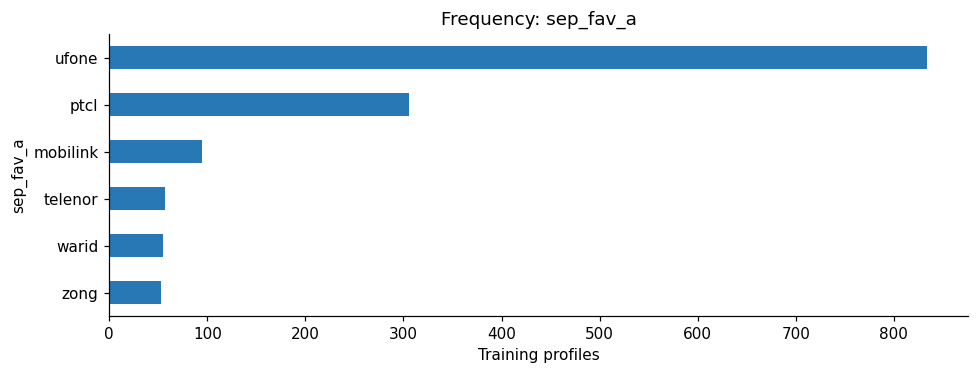

In [23]:
field = "sep_fav_a"
labels = eda[field].fillna("Missing")
freq = labels.value_counts()
focus = freq.idxmax()
sample(eda.loc[labels.eq(focus), [field, "Class"]])
table(freq.rename_axis("category").reset_index(name="records"))
fig, ax = plt.subplots(figsize=(9, max(3.5, len(freq) * 0.35)))
freq.sort_values().plot.barh(ax=ax, color="#2878b5")
ax.set(xlabel="Training profiles", title="Frequency: " + field)
finish("cat_sep_fav_a")


**Ví dụ tính từ dữ liệu:**

ufone: 834/1400=59,57%

**Nhận xét:** Nhóm ufone có nhiều hồ sơ nhất: 834/1400, tương đương 59,57%. Hình này mới cho biết nhóm nào đông; phần 7 sẽ xem tỷ lệ đã rời dịch vụ trong từng nhóm.

## 7. Hai nhóm khách hàng khác nhau ở đâu?
Sau khi biết nhóm nào đông, ta xem **trong mỗi nhóm có bao nhiêu khách đã rời dịch vụ**. Luôn đọc cả số hồ sơ và tỷ lệ: tỷ lệ của một nhóm nhỏ dễ thay đổi hơn khi thêm vài hồ sơ.

Các con số chỉ mô tả bộ dữ liệu đã được tác giả cân bằng. Chúng giúp tìm thông tin có thể hữu ích cho mô hình, chưa cho biết yếu tố nào là nguyên nhân khiến khách rời đi.

### 7.1.1. Tỷ lệ đã rời dịch vụ theo loại dịch vụ tháng 8
Với từng nhóm, lấy **số khách đã rời / tổng khách trong nhóm × 100**. Bảng `n`, `positive`, `rate` lần lượt là số khách nhóm, số đã rời và tỷ lệ đã rời.

Đếm số khách rời thôi có thể khiến nhóm đông trông đáng chú ý hơn chỉ vì nhóm đó lớn. So tỷ lệ giúp nhìn công bằng hơn giữa các nhóm khác kích thước. Bảng 5 ví dụ minh họa các nhãn thật; tỷ lệ vẫn tính trên toàn nhóm.

aug_user_type,Class
2G,1
2G,1
2G,0
2G,0
2G,0


group,n,positive,rate
3G,684,304,"0,44"
Missing,159,74,"0,47"
Other,262,151,"0,58"
2G,295,171,"0,58"


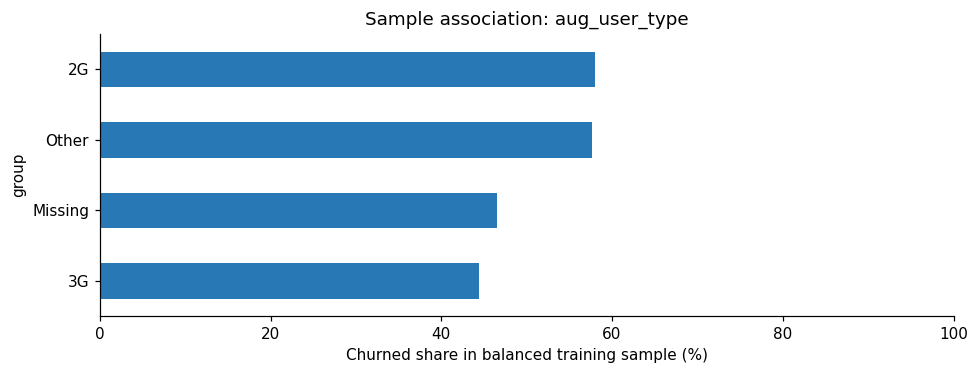

In [24]:
field = "aug_user_type"
labels = eda[field].fillna("Missing")
rates = (
    eda.assign(group=labels)
    .groupby("group")
    .Class.agg(n="size", positive="sum", rate="mean")
    .sort_values("rate")
)
focus = rates.index[-1]
r = rates.loc[focus]
sample(eda.loc[labels.eq(focus), [field, "Class"]])
table(rates.reset_index())
fig, ax = plt.subplots(figsize=(9, max(3.5, len(rates) * 0.35)))
(100 * rates.rate).plot.barh(ax=ax, color="#2878b5")
ax.set(
    xlabel="Churned share in balanced training sample (%)",
    xlim=(0, 100),
    title="Sample association: " + field,
)
finish("rate_aug_user_type")


**Ví dụ tính từ dữ liệu:**

2G: 171/295=57,97%

**Nhận xét:** Nhóm 2G có 171/295 khách đã rời dịch vụ (57,97%); nhóm 3G có 304/684 (44,44%). Chênh lệch là 13,52 điểm phần trăm trong bộ dữ liệu này. Cần đọc số khách bên cạnh tỷ lệ, nhất là nhóm nhỏ.

### 7.1.2. Tỷ lệ đã rời dịch vụ theo loại dịch vụ tháng 9
Với từng nhóm, lấy **số khách đã rời / tổng khách trong nhóm × 100**. Bảng `n`, `positive`, `rate` lần lượt là số khách nhóm, số đã rời và tỷ lệ đã rời.

Đếm số khách rời thôi có thể khiến nhóm đông trông đáng chú ý hơn chỉ vì nhóm đó lớn. So tỷ lệ giúp nhìn công bằng hơn giữa các nhóm khác kích thước. Bảng 5 ví dụ minh họa các nhãn thật; tỷ lệ vẫn tính trên toàn nhóm.

sep_user_type,Class
2G,0
2G,1
2G,1
2G,0
2G,0


group,n,positive,rate
Missing,134,60,"0,45"
3G,731,331,"0,45"
Other,262,151,"0,58"
2G,273,158,"0,58"


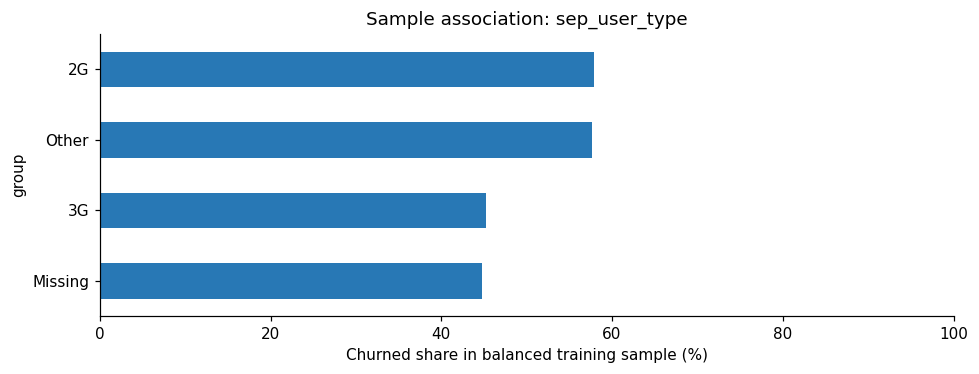

In [25]:
field = "sep_user_type"
labels = eda[field].fillna("Missing")
rates = (
    eda.assign(group=labels)
    .groupby("group")
    .Class.agg(n="size", positive="sum", rate="mean")
    .sort_values("rate")
)
focus = rates.index[-1]
r = rates.loc[focus]
sample(eda.loc[labels.eq(focus), [field, "Class"]])
table(rates.reset_index())
fig, ax = plt.subplots(figsize=(9, max(3.5, len(rates) * 0.35)))
(100 * rates.rate).plot.barh(ax=ax, color="#2878b5")
ax.set(
    xlabel="Churned share in balanced training sample (%)",
    xlim=(0, 100),
    title="Sample association: " + field,
)
finish("rate_sep_user_type")


**Ví dụ tính từ dữ liệu:**

2G: 158/273=57,88%

**Nhận xét:** Nhóm 2G có 158/273 khách đã rời dịch vụ (57,88%); nhóm Missing có 60/134 (44,78%). Chênh lệch là 13,10 điểm phần trăm trong bộ dữ liệu này. Cần đọc số khách bên cạnh tỷ lệ, nhất là nhóm nhỏ.

### 7.1.3. Tỷ lệ đã rời dịch vụ theo mạng khác được liên lạc nhiều nhất tháng 8
Với từng nhóm, lấy **số khách đã rời / tổng khách trong nhóm × 100**. Bảng `n`, `positive`, `rate` lần lượt là số khách nhóm, số đã rời và tỷ lệ đã rời.

Đếm số khách rời thôi có thể khiến nhóm đông trông đáng chú ý hơn chỉ vì nhóm đó lớn. So tỷ lệ giúp nhìn công bằng hơn giữa các nhóm khác kích thước. Bảng 5 ví dụ minh họa các nhãn thật; tỷ lệ vẫn tính trên toàn nhóm.

aug_fav_a,Class
ptcl,1
ptcl,1
ptcl,1
ptcl,1
ptcl,0


group,n,positive,rate
0,43,13,"0,30"
zong,176,73,"0,41"
telenor,198,87,"0,44"
warid,144,67,"0,47"
ufone,314,160,"0,51"
mobilink,190,97,"0,51"
ptcl,335,203,"0,61"


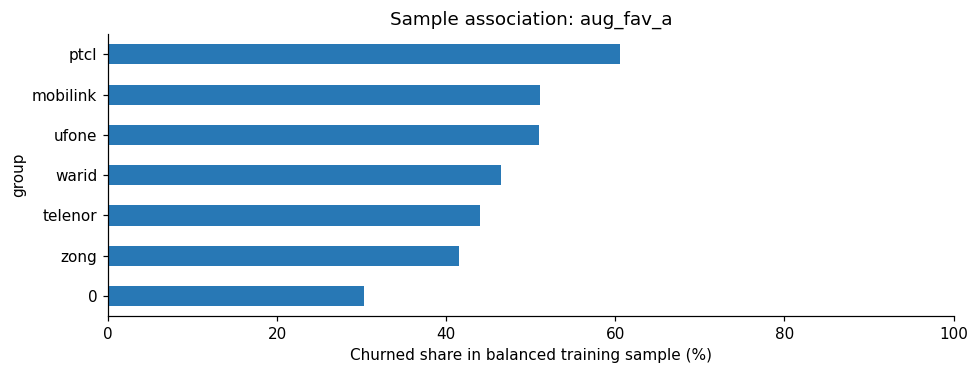

In [26]:
field = "aug_fav_a"
labels = eda[field].fillna("Missing")
rates = (
    eda.assign(group=labels)
    .groupby("group")
    .Class.agg(n="size", positive="sum", rate="mean")
    .sort_values("rate")
)
focus = rates.index[-1]
r = rates.loc[focus]
sample(eda.loc[labels.eq(focus), [field, "Class"]])
table(rates.reset_index())
fig, ax = plt.subplots(figsize=(9, max(3.5, len(rates) * 0.35)))
(100 * rates.rate).plot.barh(ax=ax, color="#2878b5")
ax.set(
    xlabel="Churned share in balanced training sample (%)",
    xlim=(0, 100),
    title="Sample association: " + field,
)
finish("rate_aug_fav_a")


**Ví dụ tính từ dữ liệu:**

ptcl: 203/335=60,60%

**Nhận xét:** Nhóm ptcl có 203/335 khách đã rời dịch vụ (60,60%); nhóm 0 có 13/43 (30,23%). Chênh lệch là 30,36 điểm phần trăm trong bộ dữ liệu này. Cần đọc số khách bên cạnh tỷ lệ, nhất là nhóm nhỏ.

### 7.1.4. Tỷ lệ đã rời dịch vụ theo mạng khác được liên lạc nhiều nhất tháng 9
Với từng nhóm, lấy **số khách đã rời / tổng khách trong nhóm × 100**. Bảng `n`, `positive`, `rate` lần lượt là số khách nhóm, số đã rời và tỷ lệ đã rời.

Đếm số khách rời thôi có thể khiến nhóm đông trông đáng chú ý hơn chỉ vì nhóm đó lớn. So tỷ lệ giúp nhìn công bằng hơn giữa các nhóm khác kích thước. Bảng 5 ví dụ minh họa các nhãn thật; tỷ lệ vẫn tính trên toàn nhóm.

sep_fav_a,Class
ptcl,1
ptcl,1
ptcl,1
ptcl,1
ptcl,1


group,n,positive,rate
ufone,834,293,"0,35"
warid,55,35,"0,64"
telenor,57,37,"0,65"
mobilink,95,63,"0,66"
zong,53,40,"0,75"
ptcl,306,232,"0,76"


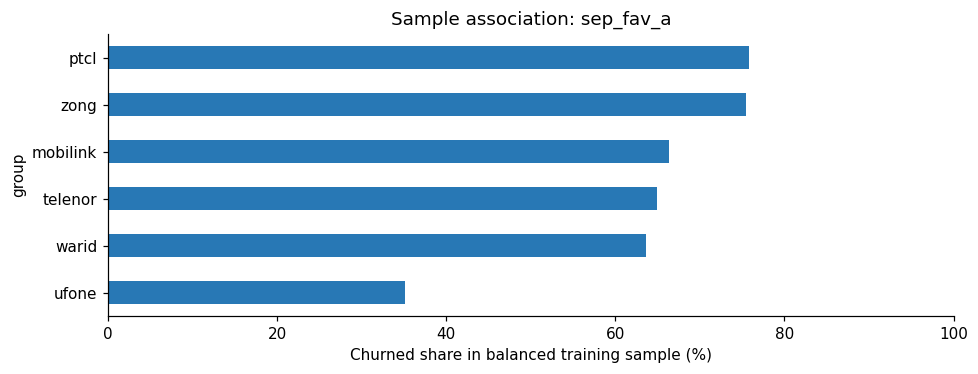

In [27]:
field = "sep_fav_a"
labels = eda[field].fillna("Missing")
rates = (
    eda.assign(group=labels)
    .groupby("group")
    .Class.agg(n="size", positive="sum", rate="mean")
    .sort_values("rate")
)
focus = rates.index[-1]
r = rates.loc[focus]
sample(eda.loc[labels.eq(focus), [field, "Class"]])
table(rates.reset_index())
fig, ax = plt.subplots(figsize=(9, max(3.5, len(rates) * 0.35)))
(100 * rates.rate).plot.barh(ax=ax, color="#2878b5")
ax.set(
    xlabel="Churned share in balanced training sample (%)",
    xlim=(0, 100),
    title="Sample association: " + field,
)
finish("rate_sep_fav_a")


**Ví dụ tính từ dữ liệu:**

ptcl: 232/306=75,82%

**Nhận xét:** Nhóm ptcl có 232/306 khách đã rời dịch vụ (75,82%); nhóm ufone có 293/834 (35,13%). Chênh lệch là 40,69 điểm phần trăm trong bộ dữ liệu này. Cần đọc số khách bên cạnh tỷ lệ, nhất là nhóm nhỏ.

### 7.2. Những đại lượng nào thường tăng hoặc giảm cùng nhau?
Ma trận tương quan đặt các cặp biến cạnh nhau. Mỗi ô chứa hệ số Pearson r, nằm từ −1 đến 1: r dương nghĩa là hai đại lượng thường tăng cùng nhau; r âm nghĩa là chúng thường đi ngược nhau; r gần 0 nghĩa là quan hệ theo đường thẳng yếu.

Bảng 5 cặp doanh thu tổng–số cuộc gọi minh họa dữ liệu được dùng. Công thức lấy tổng tích độ lệch so với trung bình rồi chia cho căn tích hai tổng bình phương độ lệch. Kết quả dùng mọi cặp có đủ dữ liệu trong tập học. Có tương quan không đồng nghĩa yếu tố này gây ra yếu tố kia.

Aggregate_Total_Rev,Aggregate_Calls
"152,45",44
"135,38",11
"1367,68",198
"682,79",27
"155,57",3


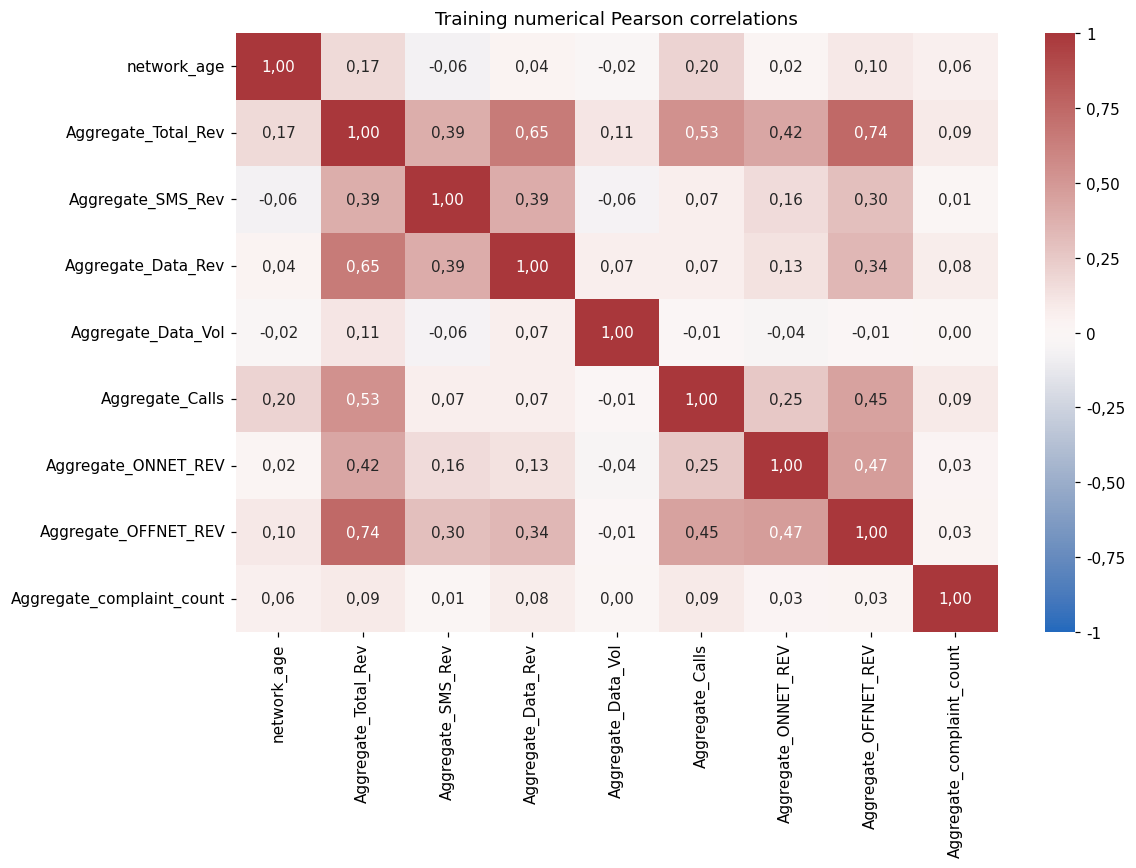

In [28]:
p = eda[["Aggregate_Total_Rev", "Aggregate_Calls"]].dropna()
a = p.Aggregate_Total_Rev
b = p.Aggregate_Calls
num = ((a - a.mean()) * (b - b.mean())).sum()
den = np.sqrt(((a - a.mean()) ** 2).sum() * ((b - b.mean()) ** 2).sum())
sample(p)
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(eda[NUM].corr(), vmin=-1, vmax=1, cmap="vlag", annot=True, fmt=".2f", ax=ax)
ax.set_title("Training numerical Pearson correlations")
finish("corr")


**Ví dụ tính từ dữ liệu:**

r=332603604,45/624610315,96=0,53; complete pairs=1400

**Nhận xét:** Doanh thu tổng và số cuộc gọi có r ≈ 0,53: trong tập học, khách gọi nhiều thường đi kèm doanh thu cao hơn, nhưng quan hệ không hoàn toàn chặt. Chưa thể từ đó suy ra cuộc gọi là nguyên nhân làm khách ở lại hoặc rời đi.

## 8. Từ các phát hiện trên, cần chuẩn bị dữ liệu thế nào?
Ta giữ đủ 2000 hồ sơ và chỉ xử lý thông tin cần thiết:

- Thời gian sử dụng âm được coi là chưa biết. Sau đó dùng trung vị của tập học để điền.
- Cột phân nhóm bị trống được thêm nhóm “chưa có thông tin” (`Missing`). Mã `Other` và `'0'` vẫn giữ ý nghĩa riêng như nguồn.
- Những giá trị rất lớn được giữ lại vì chưa có bằng chứng chúng bị nhập sai.
- Các nhóm được đổi thành cột số 0/1 bằng **one-hot encoding**. Các đại lượng số được đưa về thang đo dễ so sánh bằng **StandardScaler**.

Do nhiều đại lượng có một số giá trị rất lớn, bài thử thêm phép log1p, tức ln(1+x), để giảm chênh lệch. Ta sẽ so kết quả mô hình có/không dùng phép này; không mặc định biến đổi là tốt hơn. Các giá trị dùng để điền và chuẩn hóa đều được tính từ tập học.

### 8.1. log1p làm thay đổi cách nhìn doanh thu ra sao?
Bảng đầu cho thấy cùng 5 hồ sơ trước và sau phép ln(1+x), kèm một phép thế số cụ thể. Hai biểu đồ vẫn dùng cùng khách hàng, nhưng thang ngang khác nhau: bên trái là doanh thu gốc, bên phải là giá trị sau biến đổi.

Bảng tiếp theo so trung bình, trung vị và độ lệch của hai thang. Giá trị lớn được nén lại nên phần đông khách dễ nhìn hơn. Điều này chưa chứng minh dự đoán tốt hơn; phải xem phần so mô hình.

before,log1p
"152,45","5,03"
"135,38","4,92"
"1367,68","7,22"
"682,79","6,53"
"155,57","5,05"


scale,mean,median,skew
source,"894,70","619,22","8,81"
log1p,"6,23","6,43","-0,70"


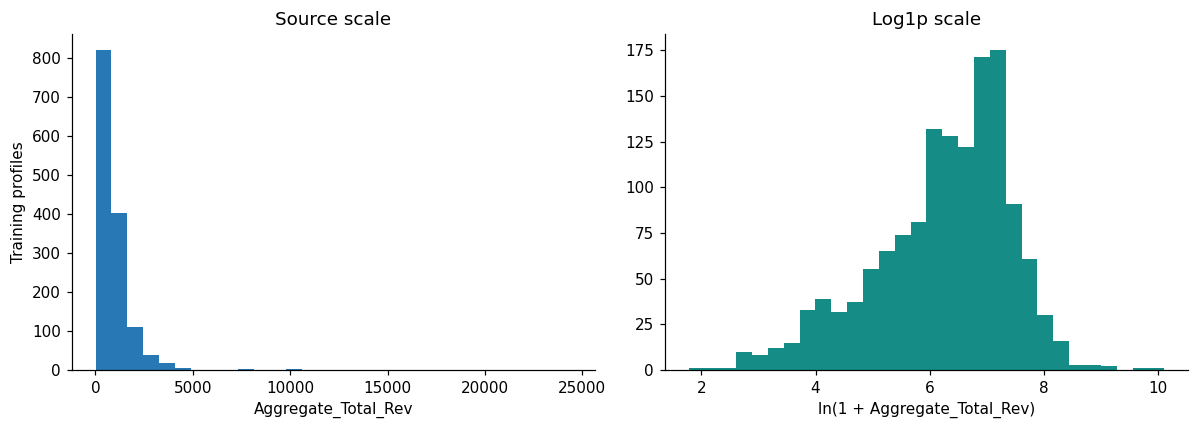

In [29]:
v = eda.Aggregate_Total_Rev
logged = np.log1p(v)
table(pd.DataFrame({"before": v.head(5), "log1p": logged.head(5)}))
table(
    pd.DataFrame(
        [
            {"scale": "source", "mean": v.mean(), "median": v.median(), "skew": v.skew()},
            {
                "scale": "log1p",
                "mean": logged.mean(),
                "median": logged.median(),
                "skew": logged.skew(),
            },
        ]
    )
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(v, bins=30, color="#2878b5")
axes[0].set(xlabel="Aggregate_Total_Rev", ylabel="Training profiles", title="Source scale")
axes[1].hist(logged, bins=30, color="#158c86")
axes[1].set(xlabel="ln(1 + Aggregate_Total_Rev)", title="Log1p scale")
finish("log1p")


**Ví dụ tính từ dữ liệu:**

ln(1+152,45)=5,03

**Nhận xét:** Chỉ số độ lệch thay đổi từ 8,81 xuống −0,70. Những giá trị rất lớn đã được nén lại, nên hình bên phải bớt dồn vào một cột. Dấu âm cho biết đuôi phân bố sau biến đổi nghiêng về phía giá trị nhỏ hơn; chưa có nghĩa mô hình đã tốt hơn.

## 9. Mô hình sẽ nhận những thông tin nào?
### 9.1. Tạo bảng đầu vào và xử lý thời gian âm
**X** là 13 cột thông tin khách hàng; **y** là kết quả thật trong `Class`. Mô hình học từ X để dự đoán y.

Bảng dưới chỉ ra đúng 5 giá trị thời gian âm được đổi thành ký hiệu thiếu `NaN`. Các cột khác và số hồ sơ được giữ nguyên. Sau đó code khai báo **pipeline**, tức chuỗi bước tự động: điền ô thiếu → tùy chọn log1p → chuẩn hóa số; với cột phân nhóm là điền nhóm thiếu → one-hot.

Mỗi mô hình có chuỗi xử lý riêng. Chuỗi đó học cách xử lý từ tập học, rồi áp dụng nguyên cách ấy cho hai tập kiểm tra. Mục 10.2 sẽ in các con số thực sự được đưa vào mô hình được chọn.

In [30]:
X = study.model_inputs(view)
y = view.Class.astype(int)
invalid = view.network_age.lt(0)
table(
    pd.DataFrame(
        {
            "source_row_id": view.index[invalid],
            "before": view.loc[invalid, "network_age"],
            "after": X.loc[invalid, "network_age"],
        }
    )
)
assert X.shape == (N, 13) and X.network_age.dropna().ge(0).all() and "Class" not in X
print(
    "Negative-duration changes by split:",
    {label: int(invalid.loc[idx].sum()) for label, idx in parts.items()},
)


def make_preprocessor(log_numeric=False):
    steps = [("impute", SimpleImputer(strategy="median"))]
    if log_numeric:
        steps.append(("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
    steps.append(("scale", StandardScaler()))
    return ColumnTransformer(
        [
            ("num", Pipeline(steps), NUM),
            (
                "cat",
                Pipeline(
                    [
                        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
                    ]
                ),
                CAT,
            ),
        ]
    )


source_row_id,before,after
594,-8,NaN
595,-5,NaN
596,-4,NaN
597,-3,NaN
598,-2,NaN


Negative-duration changes by split: {'train': 3, 'validation': 0, 'test': 2}


## 10. So sánh mô hình và chọn một mô hình
### 10.1. Mô hình nào nhận diện khách đã rời dịch vụ tốt hơn?
So bốn cách: **Dummy** luôn đoán một nhóm để làm mốc; **Logistic Regression** là mô hình phân loại cơ bản; **Logistic + log1p** dùng thêm phép nén số lớn; **Random Forest** kết hợp nhiều cây quyết định.

Các mô hình học từ cùng 1400 hồ sơ và được so trên cùng 300 hồ sơ validation. Bài chọn theo **F1 của nhóm đã rời dịch vụ**. Cách đọc bảng:

| Chỉ số | Câu hỏi mà chỉ số trả lời |
|---|---|
| Accuracy | Bao nhiêu phần trăm mọi hồ sơ được đoán đúng? |
| Precision | Trong số hồ sơ bị báo “đã rời dịch vụ”, bao nhiêu hồ sơ đúng là đã rời? |
| Recall | Trong số khách thật sự đã rời dịch vụ, mô hình tìm được bao nhiêu? |
| F1 | Precision và recall kết hợp tốt đến mức nào? |
| ROC-AUC | Mô hình xếp khách đã rời cao hơn khách còn hoạt động tốt đến mức nào? |
| AP | Precision được duy trì ra sao khi cố gắng tìm thêm khách đã rời? |

Các điểm này càng cao càng tốt theo từng cách đo. F1 = 2TP/(2TP+FP+FN); TP là khách đã rời được nhận diện đúng, FP là báo nhầm, FN là bỏ sót. Nếu F1 bằng nhau, chọn recall cao hơn. Ngưỡng quyết định giữ ở 0,50: điểm lớp 1 từ 0,50 trở lên được dự đoán là Churned. Năm dự đoán bên dưới chỉ minh họa; bảng chỉ số dùng đủ 300 hồ sơ.

model,accuracy,precision_churn,recall_churn,F1_churn,ROC_AUC,AP
Logistic + log1p,"0,77","0,79","0,73","0,76","0,82","0,83"
Logistic,"0,73","0,70","0,81","0,75","0,81","0,80"
Random Forest,"0,75","0,76","0,71","0,74","0,84","0,84"
Dummy,"0,50","0,00","0,00","0,00","0,50","0,50"


row_id,true_Class,prediction,score_churn
1742,1,0,"0,41"
1494,1,1,"0,75"
1119,1,1,"0,67"
970,1,1,"0,90"
1838,1,1,"0,56"


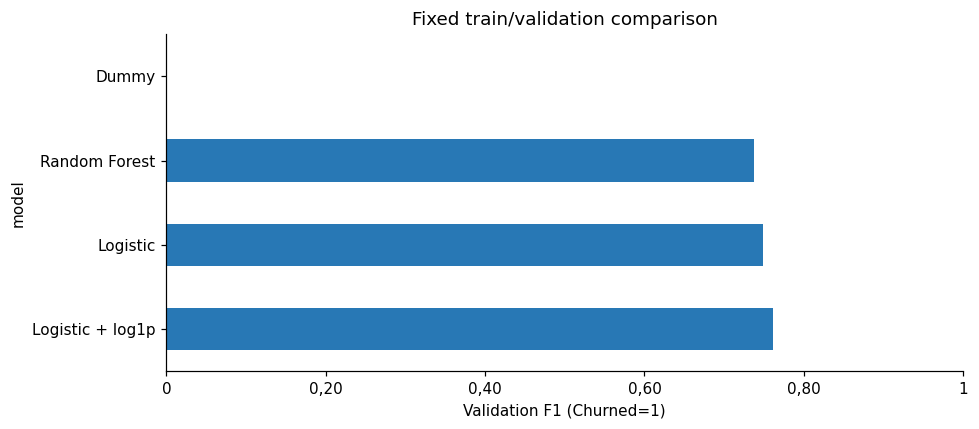

In [31]:
settings = {
    "Dummy": (DummyClassifier(strategy="most_frequent"), False),
    "Logistic": (LogisticRegression(max_iter=2000, random_state=SEED), False),
    "Logistic + log1p": (LogisticRegression(max_iter=2000, random_state=SEED), True),
    "Random Forest": (
        RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
        False,
    ),
}


def score(true, pred, prob):
    return {
        "accuracy": accuracy_score(true, pred),
        "precision_churn": precision_score(true, pred, zero_division=0),
        "recall_churn": recall_score(true, pred, zero_division=0),
        "F1_churn": f1_score(true, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(true, prob),
        "AP": average_precision_score(true, prob),
    }


models = {}
rows = []
for name, (model, use_log) in settings.items():
    pipe = Pipeline([("prep", make_preprocessor(use_log)), ("model", model)])
    pipe.fit(X.loc[train_idx], y.loc[train_idx])
    models[name] = pipe
    prob = pipe.predict_proba(X.loc[val_idx])[:, 1]
    pred = (prob >= 0.5).astype(int)
    rows.append({"model": name, **score(y.loc[val_idx], pred, prob)})
validation = pd.DataFrame(rows).sort_values(["F1_churn", "recall_churn"], ascending=False)
table(validation)
chosen = validation.iloc[0].model
vprob = models[chosen].predict_proba(X.loc[val_idx])[:, 1]
vpred = (vprob >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y.loc[val_idx], vpred, labels=[0, 1]).ravel()
sample(
    pd.DataFrame(
        {
            "row_id": val_idx,
            "true_Class": y.loc[val_idx].to_numpy(),
            "prediction": vpred,
            "score_churn": vprob,
        }
    )
)
fig, ax = plt.subplots(figsize=(9, 4))
validation.set_index("model").F1_churn.plot.barh(ax=ax, color="#2878b5")
ax.set(xlim=(0, 1), xlabel="Validation F1 (Churned=1)", title="Fixed train/validation comparison")
finish("validation")
a = validation.set_index("model").loc["Logistic"]
b = validation.set_index("model").loc["Logistic + log1p"]
validation.to_csv(OUT / "validation_metrics.csv", index=False)


**Ví dụ tính từ dữ liệu:**

Logistic + log1p: F1=2×110/(2×110+29+40)=0,76

**Nhận xét:** Logistic + log1p có F1 cao nhất trên tập chọn mô hình: 0,76. So với Logistic thường, thêm log1p tăng F1 từ 0,75 lên 0,76, nhưng tỷ lệ tìm được khách đã rời (recall) giảm từ 80,67% xuống 73,33%. Phép biến đổi có đánh đổi, không tốt hơn ở mọi chỉ số.

### 10.2. Xem đúng bảng số mà mô hình đã chọn sử dụng
Bảng trung vị cho biết giá trị dùng để điền từng cột số. Bảng 5 hàng tiếp theo là dữ liệu sau xử lý: `num__` chỉ cột số đã biến đổi; `cat__` chỉ cột 0/1 tạo từ tên nhóm. Số cột tăng lên vì mỗi loại dịch vụ hoặc tên mạng có thể tạo một cột riêng.

`source_row_id` chỉ giúp tìm lại hồ sơ gốc, không đưa vào mô hình. Phép tính phía dưới minh họa việc chuẩn hóa: lấy giá trị sau log1p (nếu mô hình có dùng), trừ trung bình tập học rồi chia cho độ lệch chuẩn tập học. Đây là cách đưa các đại lượng về cùng thang, không phải thay đổi kết quả thật của khách.

In [32]:
prep = models[chosen].named_steps["prep"]
Xt = prep.transform(X.loc[train_idx])
Xv = prep.transform(X.loc[val_idx])
Xtest = prep.transform(X.loc[test_idx])
assert all(np.isfinite(t).all() for t in [Xt, Xv, Xtest])
feature_names = prep.get_feature_names_out()
print("Selected:", chosen, "| Transformed shapes:", Xt.shape, Xv.shape, Xtest.shape)
table(
    pd.DataFrame(
        {
            "field": NUM,
            "train_median": prep.named_transformers_["num"].named_steps["impute"].statistics_,
        }
    )
)
shown = pd.DataFrame(Xt[:5], columns=feature_names)
shown.insert(0, "source_row_id", train_idx[:5])
table(shown)
num_pipe = prep.named_transformers_["num"]
j = NUM.index("Aggregate_Total_Rev")
source_value = float(X.loc[train_idx[0], "Aggregate_Total_Rev"])
before_scale = float(np.log1p(source_value)) if "log" in num_pipe.named_steps else source_value
sc = num_pipe.named_steps["scale"]
pd.DataFrame({"transformed_feature": feature_names}).to_csv(OUT / "model_features.csv", index=False)


Selected: Logistic + log1p | Transformed shapes: (1400, 30) (300, 30) (300, 30)


field,train_median
network_age,"1143,00"
Aggregate_Total_Rev,"619,22"
Aggregate_SMS_Rev,"14,34"
Aggregate_Data_Rev,"13,75"
Aggregate_Data_Vol,"176029,80"
Aggregate_Calls,"104,00"
Aggregate_ONNET_REV,"1976,50"
Aggregate_OFFNET_REV,"5097,50"
Aggregate_complaint_count,"1,00"


source_row_id,num__network_age,num__Aggregate_Total_Rev,num__Aggregate_SMS_Rev,num__Aggregate_Data_Rev,num__Aggregate_Data_Vol,num__Aggregate_Calls,num__Aggregate_ONNET_REV,num__Aggregate_OFFNET_REV,num__Aggregate_complaint_count,cat__aug_user_type_2G,cat__aug_user_type_3G,cat__aug_user_type_Missing,cat__aug_user_type_Other,cat__sep_user_type_2G,cat__sep_user_type_3G,cat__sep_user_type_Missing,cat__sep_user_type_Other,cat__aug_fav_a_0,cat__aug_fav_a_mobilink,cat__aug_fav_a_ptcl,cat__aug_fav_a_telenor,cat__aug_fav_a_ufone,cat__aug_fav_a_warid,cat__aug_fav_a_zong,cat__sep_fav_a_mobilink,cat__sep_fav_a_ptcl,cat__sep_fav_a_telenor,cat__sep_fav_a_ufone,cat__sep_fav_a_warid,cat__sep_fav_a_zong
1113,"-1,43","-1,00","-0,21","-0,95","-2,37","-0,41","0,28","-0,29","0,35","0,00","1,00","0,00","0,00","1,00","0,00","0,00","0,00","0,00","0,00","0,00","1,00","0,00","0,00","0,00","0,00","0,00","0,00","1,00","0,00","0,00"
1531,"0,23","-1,10","-0,96","-1,40","0,41","-1,21","-0,85","0,08","-0,60","0,00","0,00","0,00","1,00","0,00","0,00","0,00","1,00","0,00","1,00","0,00","0,00","0,00","0,00","0,00","1,00","0,00","0,00","0,00","0,00","0,00"
1444,"-1,63","0,83","2,03","0,29","0,57","0,50","1,06","1,24","0,35","0,00","1,00","0,00","0,00","0,00","1,00","0,00","0,00","0,00","0,00","0,00","0,00","1,00","0,00","0,00","0,00","1,00","0,00","0,00","0,00","0,00"
939,"-0,61","0,25","0,36","1,05","1,07","-0,70","0,13","0,44","-0,60","0,00","1,00","0,00","0,00","0,00","1,00","0,00","0,00","0,00","1,00","0,00","0,00","0,00","0,00","0,00","0,00","0,00","1,00","0,00","0,00","0,00"
1725,"0,21","-0,98","-0,64","0,85","0,13","-1,88","-1,75","-0,96","0,35","0,00","1,00","0,00","0,00","0,00","1,00","0,00","0,00","0,00","0,00","1,00","0,00","0,00","0,00","0,00","0,00","1,00","0,00","0,00","0,00","0,00"


**Ví dụ tính từ dữ liệu:**

Source revenue=152,45; value before scale=5,03; z=(5,03−6,23)/1,20=-1,00. StandardScaler uses ddof=0.

## 11. Kiểm tra kết quả trên những hồ sơ để riêng
### 11.1. Mô hình đoán đúng và sai bao nhiêu?
Sau khi chọn mô hình, ta kiểm tra trên **300 hồ sơ test** chưa dùng để huấn luyện hoặc chọn mô hình. Bảng 5 dự đoán giúp đọc từng trường hợp; bảng chỉ số tổng hợp đủ 300 hồ sơ.

Hình vuông bên dưới là **bảng đối chiếu dự đoán — confusion matrix**. Hàng là kết quả thật, cột là dự đoán. Hai ô trên đường chéo là đoán đúng; hai ô còn lại là nhầm. Con số trong ô là số hồ sơ. Màu thể hiện tỷ lệ trong từng hàng; đưa chuột vào để xem cả số lượng và tỷ lệ.

Trong bài này, báo nhầm là khách còn hoạt động bị đoán đã rời; bỏ sót là khách đã rời bị đoán còn hoạt động. Precision = TP/(TP+FP), recall = TP/(TP+FN). Điểm mô hình chỉ được kiểm tra trên mẫu đã cân bằng này; chưa phải xác suất rời dịch vụ đã được xác nhận cho khách hàng ngoài thực tế.

row_id,true_Class,predicted_Class,score_churn
1996,1,0,"0,45"
1469,1,0,"0,25"
244,0,1,"0,76"
440,0,0,"0,32"
562,0,0,"0,25"


model,accuracy,precision_churn,recall_churn,F1_churn,ROC_AUC,AP
Logistic + log1p,"0,76","0,79","0,71","0,74","0,82","0,82"


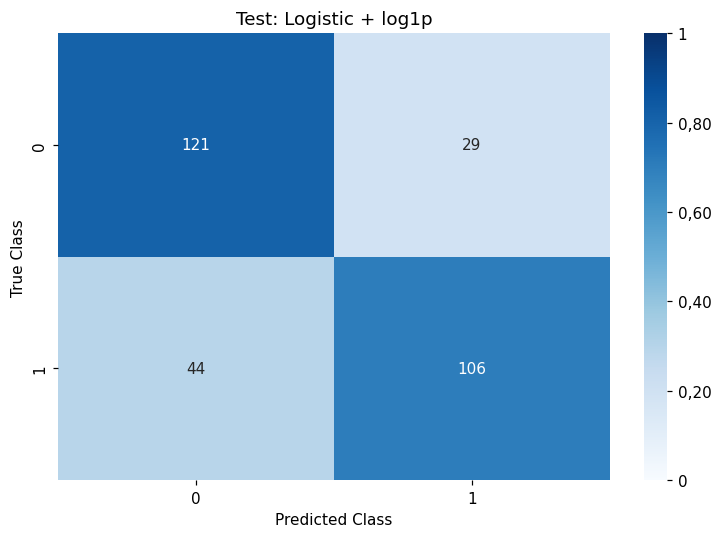

In [33]:
prob = models[chosen].predict_proba(X.loc[test_idx])[:, 1]
pred = (prob >= 0.5).astype(int)
test_metrics = score(y.loc[test_idx], pred, prob)
cm = confusion_matrix(y.loc[test_idx], pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
cases = view.loc[test_idx, FEATURES].copy()
cases.insert(0, "row_id", test_idx)
cases["true_Class"] = y.loc[test_idx]
cases["predicted_Class"] = pred
cases["score_churn"] = prob
cases["correct"] = cases.true_Class.eq(cases.predicted_Class)
sample(cases[["row_id", "true_Class", "predicted_Class", "score_churn"]])
table(pd.DataFrame([{"model": chosen, **test_metrics}]))
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    cm / cm.sum(axis=1, keepdims=True),
    annot=cm,
    fmt="d",
    vmin=0,
    vmax=1,
    cmap="Blues",
    xticklabels=[0, 1],
    yticklabels=[0, 1],
    ax=ax,
)
ax.set(xlabel="Predicted Class", ylabel="True Class", title="Test: " + chosen)
finish("confusion")
cases.to_csv(OUT / "test_predictions.csv", index=False)


**Ví dụ tính từ dữ liệu:**

Precision=106/(106+29)=0,79; recall=106/(106+44)=0,71; F1=2×106/(2×106+29+44)=0,74

**Nhận xét:** Trong 150 khách thật sự đã rời dịch vụ, mô hình tìm đúng 106 và bỏ sót 44. Trong 150 khách còn hoạt động, mô hình đoán đúng 121 nhưng báo nhầm 29 người là đã rời. Tổng cộng đoán đúng 227/300 hồ sơ (75,67%); F1 là 0,74.

### 11.2. Đọc 5 trường hợp mô hình đoán sai
`true_Class` là kết quả thật; `predicted_Class` là dự đoán. Hai cột khác nhau nghĩa là mô hình đoán sai. `score_churn` là điểm mô hình dành cho nhóm đã rời dịch vụ, dùng với ngưỡng 0,50.

Các thông tin khách trong bảng được hiển thị theo thang gốc để dễ đọc. Mô hình thực tế nhận bản đã xử lý. Những ví dụ này giúp nhìn cụ thể lỗi, nhưng chưa đủ để nói một cột nào đã gây ra lỗi đó.

In [34]:
sample(
    cases.loc[
        ~cases.correct,
        [
            "row_id",
            "network_age",
            "Aggregate_Total_Rev",
            "Aggregate_complaint_count",
            "sep_user_type",
            "true_Class",
            "predicted_Class",
            "score_churn",
        ],
    ]
)


row_id,network_age,Aggregate_Total_Rev,Aggregate_complaint_count,sep_user_type,true_Class,predicted_Class,score_churn
1996,1779,"1219,90",2,3G,1,0,"0,45"
1469,1174,"1300,94",1,Other,1,0,"0,25"
244,1038,"261,84",4,3G,0,1,"0,76"
1439,4065,"987,10",2,3G,1,0,"0,37"
1356,2051,"523,28",1,2G,0,1,"0,55"


### 11.3. Mô hình dựa vào thông tin nào nhiều hơn?
Ta thử xáo trộn giá trị của **một cột** giữa các khách hàng, giữ nguyên mô hình và các cột còn lại. Nếu F1 giảm nhiều, mô hình đang dựa đáng kể vào thông tin của cột đó. Cách thử này gọi là **permutation importance**.

Bảng 5 cặp trước/sau minh họa việc xáo trộn; phép trừ bên dưới là một lần thử. Bảng tổng hợp và biểu đồ dùng 5 lần thử cho mỗi cột trên validation: `mean` là mức giảm F1 trung bình, `std` cho biết mức thay đổi giữa các lần thử. Thanh sai số không phải khoảng tin cậy.

Kết quả cho biết mô hình đang dùng thông tin nào trong phép thử này. Những cột có liên quan với nhau có thể thay thế một phần thông tin cho nhau; vì vậy điểm nhỏ không tự động có nghĩa cột vô ích, và điểm lớn không chứng minh nguyên nhân khách rời mạng.

before,after
"812,46","434,16"
"117,27","233,64"
"403,45","336,64"
"306,29","80,12"
"509,05","1786,06"


field,F1_drop_mean,repeat_std
Aggregate_Total_Rev,"0,15","0,01"
Aggregate_SMS_Rev,"0,08","0,01"
Aggregate_OFFNET_REV,"0,04","0,01"
sep_fav_a,"0,04","0,02"
Aggregate_Data_Vol,"0,03","0,00"
network_age,"0,02","0,01"
Aggregate_Calls,"0,02","0,01"
Aggregate_ONNET_REV,"0,02","0,01"
Aggregate_Data_Rev,"0,01","0,01"
aug_user_type,"0,01","0,01"


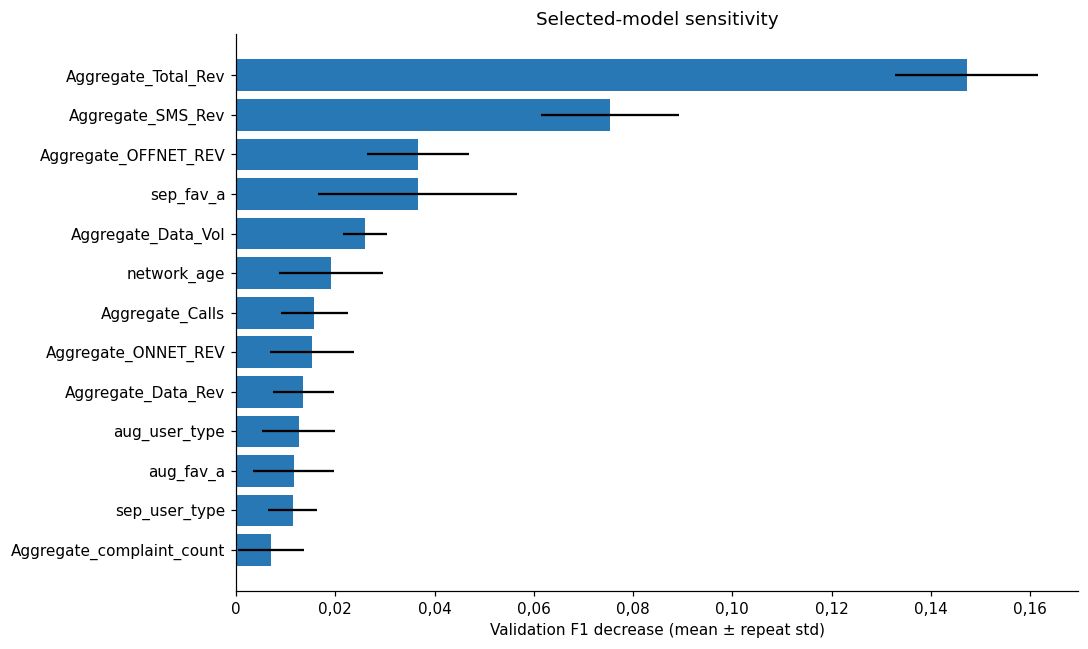

In [35]:
locked = models[chosen]
result = permutation_importance(
    locked, X.loc[val_idx], y.loc[val_idx], scoring="f1", n_repeats=5, random_state=SEED, n_jobs=1
)
imp = pd.DataFrame(
    {
        "field": FEATURES,
        "F1_drop_mean": result.importances_mean,
        "repeat_std": result.importances_std,
    }
).sort_values("F1_drop_mean", ascending=False)
focus = imp.iloc[0].field
shuffled = X.loc[val_idx].copy()
before = shuffled[focus].to_numpy().copy()
after = np.random.default_rng(SEED).permutation(before)
shuffled[focus] = after
changed = f1_score(y.loc[val_idx], locked.predict(shuffled))
base = float(validation.iloc[0].F1_churn)
table(pd.DataFrame({"before": before[:5], "after": after[:5]}))
table(imp)
p = imp.sort_values("F1_drop_mean")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(p.field, p.F1_drop_mean, xerr=p.repeat_std, color="#2878b5")
ax.axvline(0, color="gray", linewidth=1)
ax.set(xlabel="Validation F1 decrease (mean ± repeat std)", title="Selected-model sensitivity")
finish("importance")
imp.to_csv(OUT / "validation_importance.csv", index=False)


**Ví dụ tính từ dữ liệu:**

Aggregate_Total_Rev: illustrative F1 drop=0,76−0,59=0,18; table averages five separate library permutations.

**Nhận xét:** Xáo trộn cột doanh thu tổng làm F1 giảm trung bình 0,15 — mức giảm lớn nhất trong phép thử này. Mô hình đang dựa khá nhiều vào cột này. Điều đó không có nghĩa doanh thu thấp tự nó khiến khách rời mạng.

## 12. Bài này cho thấy gì và còn hạn chế gì?
Bài đã tìm hiểu dữ liệu, chỉ ra ô thiếu và thời gian âm, chuẩn bị đầu vào, so sánh bốn cách dự đoán và kiểm tra mô hình được chọn. Kết quả cụ thể được tóm tắt ngay dưới đây.

Cần đọc kết quả trong phạm vi nguồn: đây là mẫu đã được cân bằng, thiếu mã khách hàng và thời điểm ghi nhận kết quả; một số đơn vị đo chưa được giải thích đầy đủ. Vì vậy chưa thể khẳng định mô hình dự đoán tốt cho khách hàng tương lai hoặc cho toàn bộ nhà mạng. Một lần chia dữ liệu cũng chưa cho biết kết quả ổn định thế nào qua nhiều lần kiểm tra.

Dữ liệu gốc, danh sách chia tập và dự đoán từng hồ sơ được lưu để đối chiếu. Các yêu cầu nội dung được tham chiếu từ [đề assignment](Requirement/assignment-vne-v4.pdf); báo cáo PDF và video là phần nộp riêng.

In [36]:
summary = {
    "rows": N,
    "columns": raw.shape[1],
    "predictor_count": len(FEATURES),
    "positive": int(target[1]),
    "positive_rate": float(target[1] / N),
    "source_url": "https://www.kaggle.com/datasets/mahreen/sato2015",
    "input_snapshot_sha256": hashlib.sha256(raw.to_csv(index=False).encode()).hexdigest(),
    "selected_model": chosen,
    "threshold": 0.5,
    "validation": validation.to_dict(orient="records"),
    "test": test_metrics,
    "confusion_matrix": cm.tolist(),
    "split": split_table.to_dict(orient="records"),
    "transformed_features": len(feature_names),
    "figures": figures,
    "negative_duration_count": int(invalid.sum()),
}
gap = float(validation.iloc[0].F1_churn - test_metrics["F1_churn"])
(OUT / "results.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2))
assert raw.equals(snapshot)
print("Completed figures:", len(figures), "| Selected:", chosen, "| Raw unchanged")


Completed figures: 26 | Selected: Logistic + log1p | Raw unchanged


**Nhận xét:** Bài đã xử lý rõ hai vấn đề: ô trống và 5 thời gian âm. Mô hình được chọn là Logistic + log1p. Trên 300 hồ sơ kiểm tra cuối, tỷ lệ đoán đúng là 75,67%, F1=0,74. F1 thấp hơn tập chọn mô hình khoảng 0,02. Kết quả cho thấy mô hình phân biệt được hai nhóm tốt hơn mốc đoán một nhóm, nhưng vẫn còn 44 trường hợp bỏ sót và 29 trường hợp báo nhầm.